# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`ransformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

**Виконав:** Споденюк Володимир Вікторович, група ІПЗ-23-2

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### Налаштування середовища

Ставлю бібліотеки (версія `transformers` та сама, що в 4.0), монтую Google Drive і готую папки `lab3/models`, `lab3/runs`, `lab3/tokenizers` та `results.csv`. Цю клітинку треба виконати першою. Усе, що я тренуватиму й зберігатиму, лежить у `LAB_DIR`, і саме цю папку потім копіюю в репозиторій як `lab3/`.

In [1]:
# Ставимо все потрібне одним махом. Версію transformers беру ту саму, що в завданні (4.0),
# щоб у розділах 2 і 4 не було розбіжностей між середовищами.
!pip install -q "transformers[sentencepiece]==5.18.0" datasets tokenizers evaluate gradio tensorboard accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.4 MB/s eta 0:00:00


In [1]:
import os, sys, gc, json, math, time, random, re
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

# --- Де ми: Colab чи ні. У Colab кладемо все на Google Drive, щоб пережити перезапуск сесії.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    LAB_DIR = "/content/drive/MyDrive/ai_systems/lab3"
    DEMO_DIR = "/content/drive/MyDrive/ai_systems/lecture4"   # сюди пише демо-ноутбук
else:
    LAB_DIR = os.path.abspath("./lab3")
    DEMO_DIR = os.path.join(LAB_DIR, "demo_artifacts")

# Структура папок збігається з тією, яку вимагає здача: lab3/models, lab3/runs, lab3/results.csv
MODELS_DIR = os.path.join(LAB_DIR, "models")
RUNS_DIR = os.path.join(LAB_DIR, "runs")
TOK_DIR = os.path.join(LAB_DIR, "tokenizers")
for d in (LAB_DIR, MODELS_DIR, RUNS_DIR, TOK_DIR, DEMO_DIR):
    os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42


def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
print("Колаб:", IN_COLAB, "| пристрій:", device)
print("Робоча папка:", LAB_DIR)

# --- Єдина таблиця результатів (results.csv). Ключ (розділ, назва, конфіг, метрика) -> значення,
# тож повторний запуск клітинки просто перезаписує свій рядок, а не дублює його.
RESULTS_CSV = os.path.join(LAB_DIR, "results.csv")
RESULT_COLUMNS = ["section", "name", "config", "metric", "value"]
RESULTS = {}
if os.path.exists(RESULTS_CSV):
    for r in pd.read_csv(RESULTS_CSV).itertuples():
        RESULTS[(r.section, r.name, r.config, r.metric)] = r.value


def log_result(section: str, name: str, config: str, metric: str, value: float):
    RESULTS[(section, name, config, metric)] = float(value)


def save_results():
    rows = [dict(zip(RESULT_COLUMNS[:4], k), value=v) for k, v in RESULTS.items()]
    pd.DataFrame(rows, columns=RESULT_COLUMNS).to_csv(RESULTS_CSV, index=False)
    print(f"results.csv оновлено: {len(rows)} рядків -> {RESULTS_CSV}")


def free(*names: str):
    """Видаляє змінні з глобального простору імен і чистить пам'ять (RAM + GPU)."""
    g = globals()
    for n in names:
        g.pop(n, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Mounted at /content/drive
Колаб: True | пристрій: cuda
Робоча папка: /content/drive/MyDrive/ai_systems/lab3


### 0.2. Мої відповіді:

Де відповідь спирається на цифри, під нею стоїть клітинка, яка рахує їх сама й друкує підсумок. Експерименти, що потребують стану демо-ноутбука (питання 8, 10, 13), я виніс у демо як додаткові клітинки, а тут підтягую їх результати з Google Drive (`history_demo.json`, `exp_eval50.json`, `exp_thinking.json`). Тому спершу треба виконати демо, потім цей ноутбук.

Нумерацію питань залишаю такою, як у завданні (там двічі є «2» і немає «9»).

**1. Список віршів замість одного суцільного рядка**

Самі злиття BPE майже не змінилися б. Pre-tokenizer все одно ріже текст на «слова», а тренер рахує частоти пар усередині цих слів, тож словник вийшов би дуже схожим. Проблеми були б іншого роду.

Перша: пам'ять і швидкість. Тренер бере елементи ітератора порціями й обробляє їх паралельно. Один величезний рядок — це один-єдиний елемент, його не поділиш між потоками, і весь він мусить лежати в пам'яті під час підрахунку. На поезії з демо це ще терпимо, а на корпусі в сотні мегабайтів можна легко впертися в нестачу пам'яті.

Друга: межі віршів стираються. Коли вірші окремі, тренер не бачить пар «кінець одного вірша + початок наступного». У суцільному рядку такі пари з'являються й потрапляють у статистику, хоча жодного зв'язку між різними творами нема.

**2. З яких етапів складається токенізація**

Туторіал розкладає токенізатор на послідовні кроки. Своїми словами:

1. **Normalization** — чистка тексту перед усім іншим: приведення до єдиної Unicode-форми (NFC/NFKC), нижній регістр, зайві пробіли, інколи зняття акцентів. Мета: щоб однакові за змістом рядки виглядали однаково.
2. **Pre-tokenization** — грубе розбиття на «слова» (за пробілами й пунктуацією; byte-level переходить на байти; Metaspace замінює пробіл на ▁). Це жорстка межа: жоден токен не може її перетнути.
3. **Model** — сам алгоритм (BPE, WordPiece, Unigram), що ріже кожне «слово» на підслова зі свого словника. Єдиний етап, який навчається на корпусі.
4. **Post-processing** — докидає службові токени за шаблоном (`[CLS]`, `[SEP]`, `<eos>`), виставляє type ids, обрізає чи доповнює до потрібної довжини.
5. **Decoding** — зворотний шлях: з id збирає текст (склеює підслова, прибирає `##` і ▁, повертає пробіли).

Нижче маленька демонстрація перших двох етапів. З нею пов'язана українська пастка: у звичному «BERT-рецепті» нормалізації стоїть зняття акцентів, і воно псує літери «й» та «ї» (у розкладеному вигляді це «и» та «і» з діакритикою, яку зняли). Тому «йогурт» перетворюється на «иогурт».

In [3]:
from tokenizers import Regex, normalizers, pre_tokenizers

text = "  Привіт,   СВІТ!  Їжак їсть йогурт.  "

# Рецепт нормалізації «як у BERT»: NFD + нижній регістр + зняття акцентів
bert_style = normalizers.Sequence([normalizers.NFD(), normalizers.Lowercase(), normalizers.StripAccents()])
# Адаптований під українську: без зняття акцентів, плюс злипання пробілів
ukr_style = normalizers.Sequence([
    normalizers.NFKC(), normalizers.Lowercase(),
    normalizers.Replace(Regex(r"\s+"), " "), normalizers.Strip(),
])
print("вхід                       :", repr(text))
print("1. normalization (BERT)    :", repr(bert_style.normalize_str(text)), " <- «їжак» став «іжак», «йогурт» став «иогурт»")
print("1. normalization (для uk)  :", repr(ukr_style.normalize_str(text)))

normalized = ukr_style.normalize_str(text)
print()
for name, pt in [("BertPreTokenizer (слова + пунктуація)", pre_tokenizers.BertPreTokenizer()),
                 ("ByteLevel (як у GPT-2)", pre_tokenizers.ByteLevel(add_prefix_space=False)),
                 ("Metaspace (пробіл -> ▁)", pre_tokenizers.Metaspace())]:
    print(f"2. pre-tokenization, {name}:\n     {[w for w, _ in pt.pre_tokenize_str(normalized)]}")

вхід                       : '  Привіт,   СВІТ!  Їжак їсть йогурт.  '
1. normalization (BERT)    : '  привіт,   світ!  іжак ість иогурт.  '  <- «їжак» став «іжак», «йогурт» став «иогурт»
1. normalization (для uk)  : 'привіт, світ! їжак їсть йогурт.'

2. pre-tokenization, BertPreTokenizer (слова + пунктуація):
     ['привіт', ',', 'світ', '!', 'їжак', 'їсть', 'йогурт', '.']
2. pre-tokenization, ByteLevel (як у GPT-2):
     ['Ð¿ÑĢÐ¸Ð²ÑĸÑĤ', ',', 'ĠÑģÐ²ÑĸÑĤ', '!', 'ĠÑĹÐ¶Ð°Ðº', 'ĠÑĹÑģÑĤÑĮ', 'ĠÐ¹Ð¾Ð³ÑĥÑĢÑĤ', '.']
2. pre-tokenization, Metaspace (пробіл -> ▁):
     ['▁привіт,', '▁світ!', '▁їжак', '▁їсть', '▁йогурт.']


**2 (друге). Що таке `"<unk>"`, `"<eos>"` у 2.1**

Це спеціальні токени, які ми самі додаємо у словник до початку тренування. Через це вони отримують перші id (0 і 1), і алгоритм ніколи не розбиває їх на частини й не зливає з іншими.

`<unk>` (unknown) — токен «невідомо що». Якщо токенізатор зустрів символ, якого нема в його алфавіті, замість нього підставляється `<unk>`.

`<eos>` (end of sequence) — позначка кінця тексту. Ми ставимо її між віршами, щоб модель бачила, де один твір закінчується, а інший починається, і щоб під час генерації вона сама могла «сказати», що текст завершено.

**3. Менший `VOCAB_SIZE`: довжина послідовностей і `<unk>`**

Цифри — у таблиці нижче. Клітинка під відповіддю перетреновує BPE на тому ж корпусі поем при кількох розмірах словника й сама рахує середню довжину вірша та частку `<unk>`.

*Чому `<unk>` не зростає.* `<unk>` з'являється не через розмір словника, а через алфавіт: коли токенізатор зустрів символ, якого не було в початковому наборі символів. Тренування BPE стартує з цього алфавіту й далі лише додає злиття, тобто довші шматки. Менший словник означає лише те, що список злиттів обривається раніше: рідкісні довгі шматки в нього не потрапляють, і слово розпадається на дрібніші частини, у крайньому разі на окремі символи (байти). Алфавіт від цього не змінюється, нових невідомих символів не з'являється, і на тренувальному корпусі частка `<unk>` лишається нульовою. (Тонкість: алфавіт тут вчиться з самого корпусу, тож на новому тексті з незнайомим символом `<unk>` усе ж міг би з'явитися. Але до розміру словника це не має стосунку.)

*Чому зростає довжина.* Менше злиттів дає коротші токени, тож той самий вірш розпадається на більше штук. Для моделі з цього випливає два наслідки. По-перше, `CONTEXT_LEN=64` тепер покриває менше реального тексту (див. колонку «символів у вікні»), тобто модель має коротшу «пам'ять» і гірше вловлює далекі зв'язки на кшталт римування. По-друге, за той самий `MAX_ITERS` і `BATCH_SIZE` модель переглядає те саме число токенів, але вони «важать» менше тексту, тож за навчання вона бачить менший шматок змісту, а генерація вірша потребує більше кроків. З плюсів у малого словника лише менша матриця embedding/виходу і простіше передбачення кожного токена (менше класів).

In [4]:
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

# Поеми з демо (весь датасет). Тренуємо BPE тим самим кодом, що в демо 2.1,
# змінюється лише VOCAB_SIZE.
poems = load_dataset("RudyiVT/ukrainian-poems", split="train").to_pandas()["context_poem"].dropna().tolist()
CONTEXT_LEN = 64


def train_bpe_poems(vocab_size):
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    tok.train_from_iterator(poems, trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["<unk>", "<eos>"]))
    return tok


total_chars = sum(len(p) for p in poems)
rows = []
for vocab_size in (16000, 8000, 5000, 4000):
    tok = train_bpe_poems(vocab_size)
    encodings = tok.encode_batch(poems)
    lens = np.array([len(e.ids) for e in encodings])
    unk_id = tok.token_to_id("<unk>")
    unk_share = sum(e.ids.count(unk_id) for e in encodings) / lens.sum()
    chars_per_token = total_chars / lens.sum()
    rows.append({"VOCAB_SIZE": vocab_size, "реальний словник": tok.get_vocab_size(),
                 "токенів на вірш (середнє)": round(lens.mean(), 1), "частка <unk>": f"{unk_share:.3%}",
                 "символів на токен": round(chars_per_token, 2),
                 f"символів у вікні CONTEXT_LEN={CONTEXT_LEN}": round(CONTEXT_LEN * chars_per_token)})
    del tok, encodings

q3_df = pd.DataFrame(rows).set_index("VOCAB_SIZE")
display(q3_df)

big, small = rows[0], rows[2]     # 16000 проти 5000
growth = small["токенів на вірш (середнє)"] / big["токенів на вірш (середнє)"] - 1
print(f"16000 -> 5000: вірш у середньому подовжився з {big['токенів на вірш (середнє)']} до "
      f"{small['токенів на вірш (середнє)']} токенів ({growth:+.0%}); частка <unk>: {big['частка <unk>']} -> {small['частка <unk>']}.")
print(f"Вікно в {CONTEXT_LEN} токенів вміщувало ~{big[f'символів у вікні CONTEXT_LEN={CONTEXT_LEN}']} символів, "
      f"тепер вміщує ~{small[f'символів у вікні CONTEXT_LEN={CONTEXT_LEN}']}.")
del poems
free()

README.md:   0%|          | 0.00/695 [00:00<?, ?B/s]

data/train-00000-of-00001-3d92810ccd3206(…): reconstructing file:   0%|          |  0.00B / 58.6MB            

data/train-00000-of-00001-3d92810ccd3206(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/17918 [00:00<?, ? examples/s]

,реальний словник,токенів на вірш (середнє),частка <unk>,символів на токен,символів у вікні CONTEXT_LEN=64
VOCAB_SIZE,,,,,
16000,16000,1027.1,0.000%,3.31,212
8000,8000,1126.0,0.000%,3.02,193
5000,5000,1205.4,0.000%,2.82,180
4000,4000,1247.1,0.000%,2.72,174


16000 -> 5000: вірш у середньому подовжився з 1027.1 до 1205.4 токенів (+17%); частка <unk>: 0.000% -> 0.000%.
Вікно в 64 токенів вміщувало ~212 символів, тепер вміщує ~180.


**4. Навіщо `<eos>` між віршами**

Для тренування весь корпус склеюється в один довгий потік токенів, із якого беруться випадкові вікна. Без роздільника кінець одного вірша впритул стикається з початком наступного, і модель сприймає це як продовження одного тексту. Що саме піде не так:

- вона вчиться передбачати початок вірша за хвостом випадкового чужого вірша, тобто запам'ятовує зв'язки, яких насправді нема;
- вікна, що перетинають межу, змішують два незалежні твори, і attention марно дивиться на непов'язаний контекст;
- модель не отримує жодного сигналу про те, коли текст закінчується. Під час генерації вона не вміє завершити твір і тягне нескінченний потік, де вірші злипаються. З `<eos>` модель може сама видати цей токен, а ми можемо на ньому зупинити генерацію (у своїх варіантах mini-GPT я так і роблю).

**5. Формат `train_data` і `val_data`**

Це одновимірні тензори типу `int64` (`torch.long`) довжиною в кількість токенів. Кожен елемент — не слово і не вектор, а одне ціле число: id токена в словнику (від 0 до `VOCAB_SIZE-1`), зокрема й id `<eos>` між віршами. По суті, весь корпус, переведений токенізатором у числа й записаний одним довгим рядком.

`train_data` — перші 90% цього рядка, `val_data` — останні 10%. Ділимо послідовно, без перемішування, тому валідація складається з віршів, яких модель під час тренування не бачила. Тип `int64` потрібен, бо ці числа далі йдуть в `nn.Embedding` як індекси, а той приймає саме цілі `long`. В embedding-вектори id перетворюються вже всередині моделі.

**6. `assert`-тест батча**

Тест я дописав у клітинку 3.2 демо-ноутбука. Ідея така. У задачі «передбач наступний токен» `y` — це той самий фрагмент, що й `x`, лише зсунутий на один токен уперед, тобто `x[:, 1:]` має збігатися з `y[:, :-1]`. Окрім цього перевіряю форму `(BATCH_SIZE, CONTEXT_LEN)` і те, що кожен рядок батча справді є шматком корпусу. Щоб знати, з яких позицій `get_batch` його взяв, відтворюю ті самі випадкові індекси через однаковий seed.

Нижче та сама перевірка на штучному корпусі, щоб ця клітинка запускалась без жодних даних.

In [5]:
# Те саме, що я дописав у демо (клітинка 3.2), але на штучному корпусі, щоб ця клітинка
# працювала без жодних даних: токен №i має id = 3*i, тож усі зсуви видно «на око».
CONTEXT_LEN, BATCH_SIZE = 8, 4
train_data = torch.arange(1000) * 3
val_data = torch.arange(1000, 1200) * 3


def get_batch(split: str):          # без змін відносно демо
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])
    return x, y


for split, source in (("train", train_data), ("val", val_data)):
    torch.manual_seed(123)
    xb, yb = get_batch(split)
    torch.manual_seed(123)
    check_ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))     # ті самі випадкові індекси

    assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN), "неправильна форма батчу"
    assert torch.equal(xb[:, 1:], yb[:, :-1]), "y має бути x, зсунутим на 1 токен уперед"
    for row, i in enumerate(check_ix.tolist()):
        assert torch.equal(xb[row], source[i:i + CONTEXT_LEN]), f"рядок {row}: x — не шматок корпусу"
        assert torch.equal(yb[row], source[i + 1:i + CONTEXT_LEN + 1]), f"рядок {row}: y — не шматок корпусу"
    assert (yb[:, -1] == xb[:, -1] + 3).all()   # останній таргет — це справді наступний токен після вікна
    print(f"[{split}] assert-тест пройдено. Перший рядок: x={xb[0].tolist()}  y={yb[0].tolist()}")

[train] assert-тест пройдено. Перший рядок: x=[2052, 2055, 2058, 2061, 2064, 2067, 2070, 2073]  y=[2055, 2058, 2061, 2064, 2067, 2070, 2073, 2076]
[val] assert-тест пройдено. Перший рядок: x=[3213, 3216, 3219, 3222, 3225, 3228, 3231, 3234]  y=[3216, 3219, 3222, 3225, 3228, 3231, 3234, 3237]


**7. Чому `causal_mask` нижньотрикутна**

У матриці `scores` рядок — це позиція-запит `t`, стовпчик — позиція-ключ `s`. Нижній трикутник (`s <= t`) означає: токен на позиції `t` бачить себе та всі попередні, а майбутні для нього закриті. Саме так працює мовна модель: щоб передбачити наступне слово, ти знаєш лише те, що вже написано. Верхньотрикутна маска дала б навпаки: бачити тільки майбутнє й ховати минуле. Це безглуздо.

Якби маски не було, то під час тренування токен на позиції `t` міг би підглядати в позицію `t+1`, а це і є правильна відповідь (`y[t] = x[t+1]`). Модель просто навчилась би копіювати її через attention, loss швидко впав би майже до нуля, і про мову вона б нічого не вивчила. При генерації майбутніх токенів нема, тож те, на що модель спиралась, зникає, і текст виходить сміттєвим. Підступніше те, що `val_loss` теж був би хибно гарним, бо витік працює й там: за метрикою проблему не побачиш, її видно лише коли дивишся на згенерований текст.

In [6]:
torch.manual_seed(0)
T = 5
scores = torch.randn(T, T)                       # «сирі» оцінки: рядок t — запит позиції t, стовпчик s — ключ позиції s
mask = torch.tril(torch.ones(T, T))
with_mask = F.softmax(scores.masked_fill(mask == 0, float("-inf")), dim=-1)
no_mask = F.softmax(scores, dim=-1)
torch.set_printoptions(precision=2, sci_mode=False)
print("маска:\n", mask)
print("\nваги уваги З маскою (позиція t бачить лише s <= t):\n", with_mask)
print("\nваги уваги БЕЗ маски (кожна позиція дивиться і в майбутнє):\n", no_mask)

маска:
 tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])

ваги уваги З маскою (позиція t бачить лише s <= t):
 tensor([[1.00, 0.00, 0.00, 0.00, 0.00],
        [0.73, 0.27, 0.00, 0.00, 0.00],
        [0.63, 0.19, 0.18, 0.00, 0.00],
        [0.07, 0.04, 0.28, 0.60, 0.00],
        [0.47, 0.17, 0.11, 0.02, 0.23]])

ваги уваги БЕЗ маски (кожна позиція дивиться і в майбутнє):
 tensor([[0.07, 0.07, 0.18, 0.15, 0.53],
        [0.39, 0.14, 0.02, 0.27, 0.17],
        [0.42, 0.13, 0.12, 0.24, 0.09],
        [0.07, 0.04, 0.26, 0.55, 0.08],
        [0.47, 0.17, 0.11, 0.02, 0.23]])


**8. Найкращий чекпоінт проти останнього**

Збігаються вони тоді, коли `val_loss` знижується (або принаймні досягає свого мінімуму) на самому кінці тренування: найкращий момент і є останнім. Розходяться, коли мінімум `val_loss` припав на раніший момент. Після нього модель починає заучувати тренувальні дані: `train_loss` ще падає, а `val_loss` повзе вгору. Це перенавчання. Є й дрібніший випадок: крива вийшла на плато, а оцінка по 50 батчах шумить, тому «найкраща» точка випадково опиняється трохи раніше за останню, хоча реальної різниці нема.

Який випадок у мене вийшов на демо, друкує клітинка нижче (вона читає `history_demo.json`, який демо-ноутбук зберігає в клітинці 3.8).

In [7]:
hist_path = os.path.join(DEMO_DIR, "history_demo.json")
if not os.path.exists(hist_path):
    print("Файл", hist_path, "не знайдено: спершу виконайте демо-ноутбук (там він створюється в 3.8).")
else:
    h = json.load(open(hist_path))
    k = h["iters"].index(h["best_iter"])
    last = len(h["iters"]) - 1
    print(f"Найкращий чекпоінт: iter {h['best_iter']}, val_loss = {h['val'][k]:.3f}, train_loss = {h['train'][k]:.3f}")
    print(f"Останній чекпоінт:  iter {h['iters'][last]}, val_loss = {h['val'][last]:.3f}, train_loss = {h['train'][last]:.3f}")
    diff = h["val"][last] - h["val"][k]
    if k == last:
        print("\nМій випадок: чекпоінти ЗБІГАЮТЬСЯ. val_loss знижувався аж до кінця, перенавчання не було.")
    elif diff < 0.02:
        print(f"\nМій випадок: чекпоінти різні, але val_loss відрізняється лише на {diff:.3f}. Це в межах шуму оцінки "
              f"(усереднення по 50 батчах): крива вийшла на плато, а не почала переучуватись.")
    else:
        print(f"\nМій випадок: чекпоінти РОЗІЙШЛИСЯ. Мінімум val_loss був на iter {h['best_iter']}, "
              f"до кінця val виріс на {diff:.3f}, а train за цей час {'впав' if h['train'][last] < h['train'][k] else 'не впав'}: "
              f"це класичне перенавчання.")

Найкращий чекпоінт: iter 7999, val_loss = 5.652, train_loss = 5.580
Останній чекпоінт:  iter 7999, val_loss = 5.652, train_loss = 5.580

Мій випадок: чекпоінти ЗБІГАЮТЬСЯ. val_loss знижувався аж до кінця, перенавчання не було.


**10. `EVAL_INTERVAL` у 5 разів менший (250 → 50)**

*Крива.* Точок стало в 5 разів більше (було 33, стало 161), тож початок тренування, де loss падає найшвидше, видно детальніше. Але *гладкішою* крива не стала: частка «підстрибувань» `val_loss` після ітерації 1000 зросла з 7% до 36%. Кожна точка це середнє лише по 50 батчах, тобто вона містить шум. Коли справжній прогрес між сусідніми точками менший за цей шум (на пізніх етапах так і є), лінія стає зубчастою. Найкращий `val_loss` майже не змінився (5.652 → 5.648), тож про саму модель нова крива нічого нового не сказала. Інформативнішою вона стала на початку, а гладшою — ні.

*Ціна.* Одна оцінка це `2 × EVAL_ITERS = 100` прямих проходів без backward. Навчальний крок це прямий і зворотний прохід, а зворотний дорожчий за прямий, тож крок коштує приблизно втричі більше за один прямий прохід, і за теорією оцінка дорівнює близько 30 крокам. Заміряно трохи більше: одна оцінка тривала 1.6 с, чисте тренування 8000 кроків 5.8 хв (близько 0.04 с на крок), тобто оцінка коштує як ≈ 37 кроків. З цього виходять такі підсумки (рахунок за заміряним часом оцінки):

| EVAL_INTERVAL | оцінок | час тренування | накладні витрати на оцінку |
|---|---|---|---|
| 250 | 33 | ≈ 6.7 хв | 15% |
| 50 | 161 | ≈ 10.2 хв (так і вийшло у прогоні) | 75% |
| 10 | 801 | ≈ 27.4 хв | 371% |

*Чи є сенс іти нижче.* Ні. Нової інформації майже не додається (сусідні точки майже однакові), шум оцінки не зменшується (він залежить від `EVAL_ITERS`, а не від частоти), а час росте майже лінійно: при інтервалі 10 оцінки вже коштують утричі більше за саме тренування. Якщо потрібна гладка крива, розумніше збільшити `EVAL_ITERS` або згладити криву ковзним середнім під час побудови.

Точок на кривій:  EVAL_INTERVAL=250: 33   |   EVAL_INTERVAL=50: 161
Частка «підстрибувань» val_loss після iter 1000: 7% -> 36%   (чим більше, тим зубчастіша крива)
Найкращий val_loss: 5.652 (iter 7999) -> 5.648 (iter 7950)

Один виклик estimate_loss() = 1.6 с; чисте тренування 5.8 хв.
  EVAL_INTERVAL=250:   33 оцінок -> ~  6.7 хв (накладні витрати на оцінку: 15% від часу тренування)
  EVAL_INTERVAL= 50:  161 оцінок -> ~ 10.2 хв (накладні витрати на оцінку: 75% від часу тренування)
  EVAL_INTERVAL= 10:  801 оцінок -> ~ 27.4 хв (накладні витрати на оцінку: 371% від часу тренування)


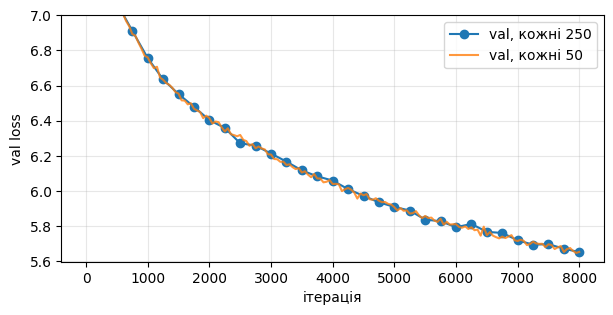

In [8]:
fast_path = os.path.join(DEMO_DIR, "exp_eval50.json")
hist_path = os.path.join(DEMO_DIR, "history_demo.json")
if not (os.path.exists(fast_path) and os.path.exists(hist_path)):
    print("Результатів експерименту ще нема: виконайте демо-ноутбук повністю (клітинки 3.8 і 3.11).")
else:
    base, fast = json.load(open(hist_path)), json.load(open(fast_path))

    def upticks(iters, vals, start=1000):
        v = [x for i, x in zip(iters, vals) if i >= start]
        return sum(b > a for a, b in zip(v, v[1:])) / max(1, len(v) - 1)

    n_base = len(base["iters"])
    print(f"Точок на кривій:  EVAL_INTERVAL={base['eval_interval']}: {n_base}   |   EVAL_INTERVAL={fast['eval_interval']}: {len(fast['iters'])}")
    print(f"Частка «підстрибувань» val_loss після iter 1000: {upticks(base['iters'], base['val']):.0%} -> "
          f"{upticks(fast['iters'], fast['val']):.0%}   (чим більше, тим зубчастіша крива)")
    print(f"Найкращий val_loss: {base['best_val_loss']:.3f} (iter {base['best_iter']}) -> "
          f"{fast['best_val_loss']:.3f} (iter {fast['best_iter']})")

    t_train, t_eval = fast["train_seconds"], fast["seconds_per_eval"]
    def n_evals(interval, total=fast["max_iters"]):
        return len(range(0, total, interval)) + (0 if (total - 1) % interval == 0 else 1)
    print(f"\nОдин виклик estimate_loss() = {t_eval:.1f} с; чисте тренування {t_train / 60:.1f} хв.")
    for interval in (250, 50, 10):
        total_min = (t_train + n_evals(interval) * t_eval) / 60
        print(f"  EVAL_INTERVAL={interval:>3}: {n_evals(interval):>4} оцінок -> ~{total_min:5.1f} хв "
              f"(накладні витрати на оцінку: {n_evals(interval) * t_eval / t_train:.0%} від часу тренування)")

    plt.figure(figsize=(7, 3.2))
    plt.plot(base["iters"], base["val"], "o-", label=f"val, кожні {base['eval_interval']}")
    plt.plot(fast["iters"], fast["val"], "-", alpha=.8, label=f"val, кожні {fast['eval_interval']}")
    plt.ylim(min(fast["val"]) - 0.05, min(max(fast["val"]), 7))
    plt.xlabel("ітерація"); plt.ylabel("val loss"); plt.legend(); plt.grid(alpha=.3); plt.show()

**11. Що робить `temperature`**

На кожному кроці модель видає вектор логітів `z` (по одному числу на токен словника). Зазвичай ймовірності рахуються як `p_i = e^{z_i} / Σ_j e^{z_j}`. Температура просто ділить логіти перед softmax:

`p_i = e^{z_i / T} / Σ_j e^{z_j / T}`

Відношення ймовірностей двох токенів тепер `p_i / p_j = e^{(z_i − z_j) / T}`, тобто різниця логітів стискається в `T` разів (при `T > 1`) або розтягується (при `T < 1`). Коли `T → 0`, найбільший логіт перемагає з величезним відривом, і розподіл вироджується в argmax (жадібна, майже детермінована генерація). Тому при 0.2 текст передбачуваний і схильний до повторів. При `T = 1` маємо «чесний» розподіл моделі. Коли `T → ∞`, усі `z_i / T → 0`, `e^0 = 1`, і розподіл наближається до рівномірного `1 / V`, тобто токени стають майже рівноімовірними.

*Чому при 1.4 текст розсипається.* Словник великий (у Qwen понад 150 тисяч токенів). Кожен окремий «поганий» токен дуже малоймовірний, але їх сотні тисяч, і разом вони тримають помітну масу. Підвищення температури роздуває цей хвіст: у модельному прикладі з клітинки нижче при `T = 1` усі інші токени разом мають частки відсотка, а при `T = 1.4` — уже близько п'ятої частини всієї маси. Тобто приблизно кожен п'ятий токен береться з «хвоста». До того ж помилка накопичується: випадковий токен стає контекстом для наступних кроків, модель з'їжджає, і текст розсипається.

In [9]:
def softmax_T(z, T):
    e = np.exp((z - z.max()) / T)       # віднімаємо max лише для числової стабільності
    return e / e.sum()


# 1) Маленький приклад: 5 слів
logits = np.array([4.0, 2.0, 1.0, 0.0, -1.0])
print("логіти:", logits, "| ентропія рівномірного розподілу:", round(float(np.log(len(logits))), 2))
for T in (0.2, 1.0, 1.4, 5.0, 50.0):
    p = softmax_T(logits, T)
    print(f"T={T:>4}: p={np.round(p, 3)}  p(топ-1)={p.max():.3f}  ентропія={-(p * np.log(p + 1e-12)).sum():.2f}")

# 2) Ближче до реальності: словник на 150 000 токенів, один явний фаворит і довгий «хвіст» дурниць
rng = np.random.default_rng(0)
z = np.concatenate([[20.0], rng.normal(0, 2.0, 150_000)])
print("\nСловник 150 000 токенів, один сильний фаворит:")
for T in (0.2, 1.0, 1.4, 3.0):
    p = softmax_T(z, T)
    print(f"T={T:>3}: p(фаворит)={p[0]:.4f}, сумарна ймовірність усіх інших 150 000 токенів = {1 - p[0]:.4f}")

логіти: [ 4.  2.  1.  0. -1.] | ентропія рівномірного розподілу: 1.61
T= 0.2: p=[1. 0. 0. 0. 0.]  p(топ-1)=1.000  ентропія=0.00
T= 1.0: p=[0.826 0.112 0.041 0.015 0.006]  p(топ-1)=0.826  ентропія=0.63
T= 1.4: p=[0.693 0.166 0.081 0.04  0.019]  p(топ-1)=0.693  ентропія=0.96
T= 5.0: p=[0.329 0.221 0.181 0.148 0.121]  p(топ-1)=0.329  ентропія=1.55
T=50.0: p=[0.211 0.203 0.199 0.195 0.191]  p(топ-1)=0.211  ентропія=1.61

Словник 150 000 токенів, один сильний фаворит:
T=0.2: p(фаворит)=1.0000, сумарна ймовірність усіх інших 150 000 токенів = 0.0000
T=1.0: p(фаворит)=0.9977, сумарна ймовірність усіх інших 150 000 токенів = 0.0023
T=1.4: p(фаворит)=0.7930, сумарна ймовірність усіх інших 150 000 токенів = 0.2070
T=3.0: p(фаворит)=0.0042, сумарна ймовірність усіх інших 150 000 токенів = 0.9958


**12. За що відповідає `top_p`**

Це nucleus sampling. Токени сортуються за ймовірністю від найбільшої; береться найменша група зверху, сумарна ймовірність якої досягає `top_p`; усе поза групою обнуляється, решта перенормовується до суми 1, і вже з неї модель випадково вибирає наступний токен. Тобто `top_p` задає, яку частку «ймовірнісної маси» ми лишаємо в грі. При `top_p = 0.1` лишається майже лише лідер (часто один токен), це близько до жадібного вибору, а `top_p = 0.95` відсікає тільки дуже довгий хвіст дурниць.

Відмінність від `top_k`: той завжди лишає рівно `k` токенів, а розмір групи в `top_p` підлаштовується під впевненість моделі. Коли вона впевнена, у групі один-два токени; коли вагається — їх багато. У бібліотеці спершу застосовується `temperature` (міняє форму розподілу), а потім `top_p` обрізає хвіст. Тому пара (0.2, 0.1) у 4.2 майже детермінована, а (1.4, 0.8) хоч і обрізає хвіст, але після `T = 1.4` розподіл такий плаский, що 80% маси набираються з великої кількості токенів.

In [10]:
def nucleus(probs, top_p):
    """top-p: найменша множина найімовірніших токенів із сумарною ймовірністю >= top_p."""
    order = np.argsort(-probs)
    k = min(int(np.searchsorted(np.cumsum(probs[order]), top_p)) + 1, len(probs))
    kept = np.zeros_like(probs)
    kept[order[:k]] = probs[order[:k]]
    return kept / kept.sum(), k          # решту обнуляємо і перенормовуємо


vocab = ["він", "вона", "ми", "вони", "ти", "я", "воно", "хтось"]
p0 = softmax_T(np.array([3.0, 2.2, 1.5, 1.0, 0.5, 0.2, -0.5, -1.0]), 0.8)     # розподіл після temperature=0.8
show = lambda p: {w: round(float(x), 3) for w, x in zip(vocab, p)}
print("вихідний розподіл:", show(p0), "\n")
for top_p in (0.1, 0.6, 0.8, 0.95, 1.0):
    p, k = nucleus(p0, top_p)
    print(f"top_p={top_p:<4} лишається токенів: {k}   нові ймовірності: {show(p)}")

вихідний розподіл: {'він': 0.589, 'вона': 0.217, 'ми': 0.09, 'вони': 0.048, 'ти': 0.026, 'я': 0.018, 'воно': 0.007, 'хтось': 0.004} 

top_p=0.1  лишається токенів: 1   нові ймовірності: {'він': 1.0, 'вона': 0.0, 'ми': 0.0, 'вони': 0.0, 'ти': 0.0, 'я': 0.0, 'воно': 0.0, 'хтось': 0.0}
top_p=0.6  лишається токенів: 2   нові ймовірності: {'він': 0.731, 'вона': 0.269, 'ми': 0.0, 'вони': 0.0, 'ти': 0.0, 'я': 0.0, 'воно': 0.0, 'хтось': 0.0}
top_p=0.8  лишається токенів: 2   нові ймовірності: {'він': 0.731, 'вона': 0.269, 'ми': 0.0, 'вони': 0.0, 'ти': 0.0, 'я': 0.0, 'воно': 0.0, 'хтось': 0.0}
top_p=0.95 лишається токенів: 5   нові ймовірності: {'він': 0.607, 'вона': 0.223, 'ми': 0.093, 'вони': 0.05, 'ти': 0.027, 'я': 0.0, 'воно': 0.0, 'хтось': 0.0}
top_p=1.0  лишається токенів: 8   нові ймовірності: {'він': 0.589, 'вона': 0.217, 'ми': 0.09, 'вони': 0.048, 'ти': 0.026, 'я': 0.018, 'воно': 0.007, 'хтось': 0.004}


**13. `enable_thinking=True`**

Цей параметр керує шаблоном чату Qwen3. При `False` шаблон одразу вставляє порожній блок `<think></think>`, і модель відповідає без роздумів. При `True` модель спершу пише міркування всередині `<think>...</think>` і лише потім фінальну відповідь.

Що вийшло в моєму запуску (таблиця з клітинки нижче):

- на всіх трьох парах `temperature`/`top_p` з `thinking=True` модель вичерпала весь ліміт `max_new_tokens=300` і **не встигла закінчити роздуми**: до власне продовження речення вона не дійшла. Без роздумів відповіді були значно коротшими (114–187 токенів проти 300);
- час зріс відповідно: ≈ 20 с проти 8–13 с, бо міркування це теж згенеровані токени, і за них платимо так само;
- відповідь починається з тегу `<think>` (він не є спецтокеном, тож лишається в тексті), а міркування модель вела **англійською**, хоча запит українською. Вона ще й плутала, де розташована Житомирська політехніка, і обговорювала це в роздумах;
- коли я збільшила ліміт до 1500 токенів і взяла рекомендовані для thinking-режиму `T=0.6`, `top_p=0.95`, модель витратила 1401 токен (≈ 100 с), закінчила роздуми, і лише тоді з'явилося власне продовження. Тобто результат у нього є, але коштує вдесятеро більше токенів.

Про температуру. Розробники Qwen радять для thinking-режиму близько `T=0.6`, `top_p=0.95` і не радять жадібне декодування (майже детерміноване `T=0.2`, `top_p=0.1` схильне зациклювати міркування). У моїх прогонах на 300 токенах зациклення не було видно: вони обірвались надто рано, щоб це побачити.

In [11]:
path = os.path.join(DEMO_DIR, "exp_thinking.json")
if not os.path.exists(path):
    print("Результатів ще нема: виконайте демо-ноутбук повністю (клітинка 4.3).")
else:
    exp = json.load(open(path))
    print(f"{'T / top_p':>10s} | {'режим':>14s} | токенів | секунд | закінчив «думати» за ліміт?")
    for r in exp["runs"]:
        mode = "thinking=True" if r["enable_thinking"] else "thinking=False"
        done = "—" if not r["enable_thinking"] else ("так" if r["finished_thinking"] else "НІ (ліміт токенів вичерпано)")
        print(f"{r['temperature']:>4} / {r['top_p']:<4} | {mode:>14s} | {r['new_tokens']:>7d} | {r['seconds']:>6.1f} | {done}")
    lr = exp["long_run"]
    print(f"\nДовгий прогін (thinking=True, T={lr['temperature']}, top_p={lr['top_p']}, ліміт {lr['max_new_tokens']}): "
          f"{lr['new_tokens']} токенів за {lr['seconds']:.0f} с, роздуми завершились: {'так' if lr['finished_thinking'] else 'ні'}.")
    print("Початок відповіді з роздумами:\n", lr["thinking_preview"])
    if lr["answer"]:
        print("\nФінальна відповідь після </think>:\n", lr["answer"])

 T / top_p |          режим | токенів | секунд | закінчив «думати» за ліміт?
 0.2 / 0.1  | thinking=False |     159 |   11.0 | —
 0.2 / 0.1  |  thinking=True |     300 |   20.4 | НІ (ліміт токенів вичерпано)
 0.8 / 0.6  | thinking=False |     114 |    8.1 | —
 0.8 / 0.6  |  thinking=True |     300 |   20.7 | НІ (ліміт токенів вичерпано)
 1.4 / 0.8  | thinking=False |     187 |   12.8 | —
 1.4 / 0.8  |  thinking=True |     300 |   20.4 | НІ (ліміт токенів вичерпано)

Довгий прогін (thinking=True, T=0.6, top_p=0.95, ліміт 1500): 1401 токенів за 101 с, роздуми завершились: так.
Початок відповіді з роздумами:
 <think>
Okay, the user wants me to continue the sentence: "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка..." 

First, I need to make sure I understand the context. It's a story about a student from the Kharkiv Polytechnic University (though the user wrote Житомирської, which is Kharkiv, but maybe it's a typo? Wait, Житомирська is Zhito

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

### Мій датасет

Беру **українську Вікіпедію** (`wikimedia/wikipedia`, конфіг `20231101.uk`). Причини такі. Це суцільна проза енциклопедичного стилю, тобто зовсім інший регістр, ніж поезія в демо: багато власних назв, дат, довгих складних речень. Тем безліч, тож токенізатор і модель побачать різноманітну лексику. А ще датасет офіційний і великий (кілька ГБ), тому його потрібно читати стрімом, як і радить завдання.

Беру 15 000 випадкових статей (перемішую стрім із фіксованим seed), викидаю заготовки коротші за 300 символів і обрізаю надто довгі статті до 5 000 символів, щоб списки й таблиці не домінували в корпусі. Для кодування далі використовую пачки та `int32`.

In [12]:
from datasets import load_dataset

# Мій корпус — українська Вікіпедія (wikimedia/wikipedia, дамп 2023-11-01). Вона величезна
# (кілька ГБ), тому читаємо стрімом і беремо лише частину статей.
N_ARTICLES = 15_000   # скільки статей беремо зі стріму
MIN_CHARS = 300       # занадто короткі заготовки викидаємо
MAX_CHARS = 5_000     # дуже довгі статті (списки, таблиці) обрізаємо, щоб не домінували

wiki_stream = load_dataset("wikimedia/wikipedia", "20231101.uk", split="train", streaming=True)
# shuffle на стрімі міксує порядок шардів і працює через буфер: так у вибірку потрапляють
# статті з різних тем, а не лише ті, що лежать на початку першого файлу.
wiki_stream = wiki_stream.shuffle(seed=SEED, buffer_size=10_000)

# У IterableDataset немає ні .to_pandas(), ні len(), тому спершу матеріалізуємо в список.
rows = list(wiki_stream.take(N_ARTICLES))
wiki_df = pd.DataFrame(rows)
del rows, wiki_stream

print("Колонки:", wiki_df.columns.tolist())
print("Статей зі стріму:", len(wiki_df))
wiki_df[["title", "text"]].head(3)

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Колонки: ['id', 'url', 'title', 'text']
Статей зі стріму: 15000


,title,text
0,Кубок Кременчуцького водосховища,Кубок Кременчу́цького водосховища — спортивні ...
1,Брасово,Брасово () — село у Брасовському районі Брянсь...
2,Haemomaster venezuelae,Haemomaster venezuelae (Гемомастер венесуельсь...


### Корпус і базова статистика

`docs` — список окремих статей (його віддаю тренерам токенізаторів), `corpus_text` — те саме суцільним рядком.

Статей після чистки:   12857
Розмір корпусу:        27,099,662 символів
Слів (з повторами):    3,710,360
Унікальних слів:       509,829
Довжина статті: медіана 1673, середня 2106, макс 5000


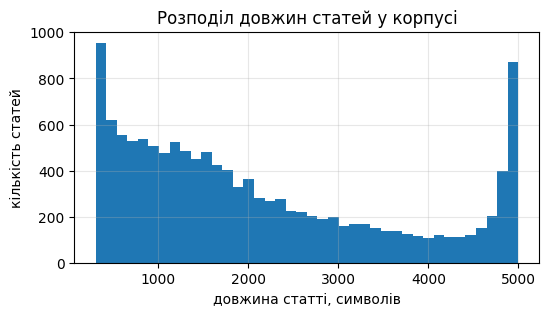


Перші 500 символів корпусу:

Кубок Кременчу́цького водосховища — спортивні змагання із вітрильного спорту серед крейсерсько-перегонових яхт. Проходять щорічно у містах України, які розташовані на березі Кременчуцького водосховища, створеного на Дніпрі. Організаторами змагань виступають Черкаська та Кіровоградська обласні федерації вітрильного спорту. Започатковані були 1986 року.

Завдання та цілі 
Згідно з регламентом змагання проводяться для:
 популяризації та розвитку вітрильного спорту в Україні;
 підвищенню спортивної 


In [13]:
def clean_article(text: str) -> str:
    text = re.sub(r"\n{3,}", "\n\n", text).strip()
    if len(text) > MAX_CHARS:
        cut = text[:MAX_CHARS]
        end = cut.rfind(". ")
        # різати бажано по кінцю речення, а не посеред слова
        text = cut[:end + 1] if end > MAX_CHARS // 2 else cut
    return text


# docs — список окремих статей (саме його ми передаємо тренеру токенізатора і кодуємо пачками),
# corpus_text — той самий текст суцільним рядком (для статистики, як у демо 1.2).
docs = [clean_article(t) for t in wiki_df["text"].dropna().astype(str)]
docs = [t for t in docs if len(t) >= MIN_CHARS]
corpus_text = "\n\n".join(docs)

words = corpus_text.split()
unique_words = set(w.lower() for w in words)
doc_lens = np.array([len(t) for t in docs])

print("Статей після чистки:  ", len(docs))
print("Розмір корпусу:       ", f"{len(corpus_text):,}", "символів")
print("Слів (з повторами):   ", f"{len(words):,}")
print("Унікальних слів:      ", f"{len(unique_words):,}")
print(f"Довжина статті: медіана {np.median(doc_lens):.0f}, середня {doc_lens.mean():.0f}, макс {doc_lens.max()}")

plt.figure(figsize=(6, 3))
plt.hist(doc_lens, bins=40)
plt.xlabel("довжина статті, символів"); plt.ylabel("кількість статей")
plt.title("Розподіл довжин статей у корпусі"); plt.grid(alpha=0.3)
plt.show()

print("\nПерші 500 символів корпусу:\n")
print(corpus_text[:500])

---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

### 2.0. Розминка: `train_new_from_iterator` (розділ 6.2)

Беру готовий токенізатор `Qwen/Qwen2.5-0.5B-Instruct` і перетреновую його на 3 000 моїх статей зі словником у 4 000 токенів. Архітектура токенізатора (byte-level BPE, pre-tokenizer, спецтокени) лишається, а словник і злиття стають «українськими». Для порівняння міряю, скільки символів у середньому припадає на токен на 200 статтях, яких ні один із токенізаторів не бачив.

In [14]:
from transformers import AutoTokenizer

# Розминка з розділу 6.2: беремо архітектуру готового токенізатора (Qwen2.5: byte-level BPE,
# той самий pre-tokenizer і набір спецтокенів) і перетреновуємо його merges/словник на своєму тексті.
def batch_iterator(texts, batch_size=500):
    for i in range(0, len(texts), batch_size):
        yield texts[i:i + batch_size]


WARMUP_VOCAB = 4000
old_tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
new_tok = old_tok.train_new_from_iterator(batch_iterator(docs[:3000]), vocab_size=WARMUP_VOCAB)
new_tok.save_pretrained(os.path.join(TOK_DIR, "qwen_uk_warmup"))

probe_docs = docs[3000:3200]   # статті, яких токенізатор не бачив
probe_chars = sum(len(t) for t in probe_docs)
sentence = "Тарас Шевченко народився в селі Моринці, а помер у Петербурзі."

for label, t in [("Qwen2.5 оригінал", old_tok), ("Qwen2.5 перетренований на uk-вікі", new_tok)]:
    n_probe = sum(len(ids) for ids in t(probe_docs)["input_ids"])
    n_sent = len(t(sentence)["input_ids"])
    print(f"{label:34s} словник {len(t):>7,} | речення: {n_sent:>2} ток. | "
          f"{probe_chars / n_probe:.2f} символів/токен на 200 нових статтях")

print("\nЯк новий токенізатор ріже речення:")
print([new_tok.decode([i]) for i in new_tok(sentence)["input_ids"]])

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Qwen2.5 оригінал                   словник 151,665 | речення: 31 ток. | 1.91 символів/токен на 200 нових статтях
Qwen2.5 перетренований на uk-вікі  словник   4,008 | речення: 23 ток. | 2.64 символів/токен на 200 нових статтях

Як новий токенізатор ріже речення:
['Т', 'ара', 'с', ' Ш', 'ев', 'ч', 'енко', ' народився', ' в', ' селі', ' М', 'ор', 'ин', 'ці', ',', ' а', ' помер', ' у', ' Пет', 'ерб', 'ур', 'зі', '.']


### 2.1. BPE вручну (розділ 6.5)

Коротка власна реалізація за туторіалом: рахую частоти слів, розкладаю їх на літери й 40 разів зливаю найчастішу пару. Це лише щоб побачити механіку, адже порівняння трьох алгоритмів нижче робить бібліотека `tokenizers`. Слова беру нижнім регістром і лише з українських літер, щоб алфавіт був малий і злиття були наочні.

In [15]:
# Розділ 6.5 «вручну»: мінімальна реалізація BPE на моєму тексті (букви + 40 злиттів).
# Це лише щоб побачити механіку, порівняння трьох алгоритмів нижче робить бібліотека tokenizers.
UK_WORD = re.compile(r"[А-Яа-яІіЇїЄєҐґ'ʼ’-]+")
word_freqs = Counter(w.lower() for t in docs[:300] for w in UK_WORD.findall(t))
alphabet = sorted({ch for w in word_freqs for ch in w})
splits = {w: list(w) for w in word_freqs}


def compute_pair_freqs(splits):
    pair_freqs = defaultdict(int)
    for w, freq in word_freqs.items():
        s = splits[w]
        for a, b in zip(s, s[1:]):
            pair_freqs[(a, b)] += freq
    return pair_freqs


def merge_pair(a, b, splits):
    for w in word_freqs:
        s = splits[w]
        i = 0
        while i < len(s) - 1:
            if s[i] == a and s[i + 1] == b:
                s = s[:i] + [a + b] + s[i + 2:]
            else:
                i += 1
        splits[w] = s
    return splits


merges = {}
manual_vocab = list(alphabet)
N_MERGES = 40
for _ in range(N_MERGES):
    pair_freqs = compute_pair_freqs(splits)
    best_pair = max(pair_freqs, key=pair_freqs.get)
    if len(merges) < 12:
        print(f"злиття #{len(merges) + 1:>2}: {best_pair[0]!r} + {best_pair[1]!r}  (частота {pair_freqs[best_pair]})")
    splits = merge_pair(*best_pair, splits)
    merges[best_pair] = best_pair[0] + best_pair[1]
    manual_vocab.append(best_pair[0] + best_pair[1])


def tokenize_manual(word: str):
    s = list(word.lower())
    for (a, b), merged in merges.items():   # злиття застосовуємо в тому порядку, в якому їх вивчили
        i = 0
        while i < len(s) - 1:
            if s[i] == a and s[i + 1] == b:
                s = s[:i] + [merged] + s[i + 2:]
            else:
                i += 1
    return s


print(f"\nрозмір словника: {len(alphabet)} букв + {len(merges)} злиттів = {len(manual_vocab)}")
for w in ["України", "університет", "електроенцефалографія"]:
    print(f"{w:24s} -> {tokenize_manual(w)}")

злиття # 1: 'н' + 'а'  (частота 5642)
злиття # 2: 'р' + 'о'  (частота 5632)
злиття # 3: 'с' + 'т'  (частота 5357)
злиття # 4: 'к' + 'о'  (частота 4844)
злиття # 5: 'е' + 'р'  (частота 4670)
злиття # 6: 'а' + 'н'  (частота 4240)
злиття # 7: 'р' + 'а'  (частота 3794)
злиття # 8: 'н' + 'и'  (частота 3576)
злиття # 9: 'в' + 'і'  (частота 3529)
злиття #10: 'н' + 'о'  (частота 3423)
злиття #11: 'г' + 'о'  (частота 3396)
злиття #12: 'н' + 'і'  (частота 3213)

розмір словника: 39 букв + 40 злиттів = 79
України                  -> ['у', 'к', 'ра', 'ї', 'ни']
університет              -> ['у', 'ні', 'в', 'ер', 'с', 'и', 'т', 'е', 'т']
електроенцефалографія    -> ['е', 'л', 'е', 'к', 'т', 'ро', 'ен', 'ц', 'е', 'ф', 'а', 'ло', 'г', 'ра', 'ф', 'і', 'я']


### 2.2. Три алгоритми на моєму тексті (розділи 6.5–6.7)

BPE, WordPiece і Unigram тренуються через бібліотеку `tokenizers` на одному й тому ж зразку (1 500 статей), з однаковим `vocab_size = 500` і однаковими спецтокенами. Кожен має «свою» природну пару pre-tokenizer + decoder (ByteLevel, BertPreTokenizer, Metaspace), як у туторіалі. Нормалізатор в усіх однаковий: NFKC без зняття акцентів (див. пастку з «й»/«ї» у питанні 2).

Зразок перед тренуванням спрощую: лишаю лише українські й латинські літери, цифри, пробіли та звичайну пунктуацію. Причина практична: у Вікіпедії тисячі різних символів (ієрогліфи, арабиця, грецька, емодзі), а Unigram-тренер видає помилку, якщо алфавіт не вміщується в словник у 500 токенів. BPE і WordPiece в такому разі помилки не дають, але мовчки роздувають словник до розміру алфавіту й не роблять жодного злиття, тож порівняння втрачає сенс. Спрощення однакове для всіх трьох алгоритмів і стосується лише цього порівняння, а не токенізатора для mini-GPT.

In [16]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers, decoders

SPECIAL = ["<unk>", "<eos>"]
CMP_VOCAB = 500               # однаковий розмір словника для чесного порівняння
# У Вікіпедії тисячі різних символів (ієрогліфи, арабиця, грецька, діакритика, емодзі...).
# Unigram-тренер вимагає, щоб словник вміщав УСІ символи тексту, а при vocab=500 це неможливо
# (звідси помилка "The vocabulary is not large enough to contain all chars"). BPE і WordPiece
# помилки не дають, але тихо роздувають словник до розміру алфавіту й лишаються без жодного
# злиття, тож порівняння було б безглуздим. Тому для ЦЬОГО порівняння лишаю у зразку лише
# українські/латинські літери, цифри, пробіли та поширену пунктуацію (однаково для всіх трьох).
NOT_ALLOWED = re.compile(r"[^А-Яа-яІіЇїЄєҐґA-Za-z0-9\s.,;:!?()\[\]«»\"'’ʼ\-–—%/&+=]")


def simplify(text: str) -> str:
    return re.sub(r"\s+", " ", NOT_ALLOWED.sub("", text)).strip()


cmp_train = [simplify(t) for t in docs[:1500]]      # на цьому тренуємо
cmp_eval = [simplify(t) for t in docs[1500:1700]]   # на цьому міряємо (текст, якого токенізатори не бачили)
alphabet_size = len(set("".join(cmp_train)))
print(f"Унікальних символів у зразку: {alphabet_size} (розмір словника: {CMP_VOCAB})")
# WordPiece зберігає кожен символ у двох виглядах (звичайний і ##-продовження), тож бюджет
# на злиття лишається, лише якщо алфавіт значно менший за словник
assert 3 * alphabet_size < CMP_VOCAB * 2, "алфавіт завеликий для такого словника: звузьте NOT_ALLOWED або збільште CMP_VOCAB"

# Нормалізатор в усіх трьох однаковий: NFKC без lowercase і БЕЗ StripAccents. У класичних рецептах
# з туторіалу є StripAccents, але для української це шкідливо: «й» і «ї» у розкладеному вигляді
# це «и»+знак і «і»+крапки, тож після зняття акцентів вони перетворюються на «и» та «і».


def build_bpe(texts, vocab_size):
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.normalizer = normalizers.NFKC()
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    tok.train_from_iterator(texts, trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIAL))
    return tok


def build_wordpiece(texts, vocab_size):
    tok = Tokenizer(models.WordPiece(unk_token="<unk>"))
    tok.normalizer = normalizers.NFKC()
    tok.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
    tok.train_from_iterator(texts, trainers.WordPieceTrainer(vocab_size=vocab_size, special_tokens=SPECIAL))
    tok.decoder = decoders.WordPiece(prefix="##")
    return tok


def build_unigram(texts, vocab_size):
    tok = Tokenizer(models.Unigram())
    tok.normalizer = normalizers.NFKC()
    tok.pre_tokenizer = pre_tokenizers.Metaspace()
    tok.train_from_iterator(
        texts, trainers.UnigramTrainer(vocab_size=vocab_size, special_tokens=SPECIAL, unk_token="<unk>")
    )
    tok.decoder = decoders.Metaspace()
    return tok


cmp_tokenizers = {
    "BPE": build_bpe(cmp_train, CMP_VOCAB),
    "WordPiece": build_wordpiece(cmp_train, CMP_VOCAB),
    "Unigram": build_unigram(cmp_train, CMP_VOCAB),
}
for name, tok in cmp_tokenizers.items():
    tok.save(os.path.join(TOK_DIR, f"cmp_{name.lower()}_{CMP_VOCAB}.json"))
    print(f"{name:10s} навчено, розмір словника = {tok.get_vocab_size()}")

Унікальних символів у зразку: 158 (розмір словника: 500)
BPE        навчено, розмір словника = 500
WordPiece  навчено, розмір словника = 500
Unigram    навчено, розмір словника = 500


### 1.1. Порівняння

Міряю на 200 статтях, яких тренування не бачило.

In [17]:
# --- допоміжне: у byte-level BPE токени виглядають як «Ð£Ð°...», тому для показу
# переводимо їх назад у нормальні символи (таблиця байт -> символ як у GPT-2).
def _bytes_to_unicode():
    bs = (list(range(ord("!"), ord("~") + 1)) + list(range(ord("¡"), ord("¬") + 1))
          + list(range(ord("®"), ord("ÿ") + 1)))
    cs, n = bs[:], 0
    for b in range(256):
        if b not in bs:
            bs.append(b)
            cs.append(256 + n)
            n += 1
    return dict(zip(bs, [chr(c) for c in cs]))


BYTE_DECODER = {ch: b for b, ch in _bytes_to_unicode().items()}


def readable(name: str, tokens):
    if name != "BPE":
        return list(tokens)
    out = []
    for t in tokens:
        try:
            out.append(bytes(BYTE_DECODER[c] for c in t).decode("utf-8", errors="replace"))
        except KeyError:
            out.append(t)
    return out


frequent_word = next(w for w, _ in Counter(UK_WORD.findall(" ".join(cmp_train))).most_common(200) if len(w) >= 7)
RARE_WORD = "електроенцефалографія"
eval_chars = sum(len(t) for t in cmp_eval)

rows, pieces = [], {}
for name, tok in cmp_tokenizers.items():
    enc = tok.encode_batch(cmp_eval)
    n_tok = sum(len(e.ids) for e in enc)
    unk_id = tok.token_to_id("<unk>")
    n_unk = sum(e.ids.count(unk_id) for e in enc)
    f_enc, r_enc = tok.encode(frequent_word), tok.encode(RARE_WORD)
    pieces[name] = (readable(name, f_enc.tokens), readable(name, r_enc.tokens))
    rows.append({
        "алгоритм": name,
        "словник": tok.get_vocab_size(),
        "токенів на зразку": n_tok,
        "токенів / 1000 симв.": round(1000 * n_tok / eval_chars, 1),
        "<unk>": n_unk,
        f"«{frequent_word}»": len(f_enc.ids),
        f"«{RARE_WORD}»": len(r_enc.ids),
    })
    cfg = f"vocab={CMP_VOCAB}"
    log_result("tokenizers", name, cfg, "tokens_on_sample", n_tok)
    log_result("tokenizers", name, cfg, "tokens_per_1000_chars", 1000 * n_tok / eval_chars)
    log_result("tokenizers", name, cfg, "unk_count", n_unk)
    log_result("tokenizers", name, cfg, "pieces_frequent_word", len(f_enc.ids))
    log_result("tokenizers", name, cfg, "pieces_rare_word", len(r_enc.ids))
save_results()

cmp_df = pd.DataFrame(rows).set_index("алгоритм")
print(f"Зразок для підрахунку: {len(cmp_eval)} статей, {eval_chars:,} символів\n")
display(cmp_df)

print("Як кожен алгоритм ріже слова (символ «�» у BPE означає, що межа токена потрапила посеред літери: у byte-level BPE одна українська літера це 2 байти):")
for name, (f_p, r_p) in pieces.items():
    print(f"  {name:10s} «{frequent_word}» -> {f_p}")
    print(f"  {'':10s} «{RARE_WORD}» -> {r_p}")

# --- короткий висновок, що рахується з таблиці (щоб текст не розходився з цифрами)
winner = cmp_df["токенів на зразку"].idxmin()
worst = cmp_df["токенів на зразку"].idxmax()
ratio = cmp_df.loc[worst, "токенів на зразку"] / cmp_df.loc[winner, "токенів на зразку"]
WHY = {
    "BPE": "BPE на кожному кроці зливає просто найчастішу пару, тобто напряму виграє на стисненні "
           "тексту, і при невеликому словнику цього вистачило, щоб обійти конкурентів.",
    "WordPiece": "WordPiece зливає не найчастішу пару, а ту, у якої частота пари найбільша відносно "
                 "частот її складових, тому у словник потрапляють змістовні шматки слів (префікси, "
                 "закінчення), які добре повторюються у різних словах.",
    "Unigram": "Unigram іде у зворотний бік: починає з великого словника і викидає ті шматки, без яких "
               "втрати на корпусі зростають найменше, а при кодуванні шукає найімовірніше розбиття; "
               "тому у словнику лишаються саме ті шматки, які добре покривають текст.",
}
print(f"\nНайкоротші послідовності дав {winner}: {cmp_df.loc[winner, 'токенів на зразку']} токенів, "
      f"тоді як {worst} дав у {ratio:.2f} раза більше.")
print(WHY[winner])

results.csv оновлено: 87 рядків -> /content/drive/MyDrive/ai_systems/lab3/results.csv
Зразок для підрахунку: 200 статей, 435,169 символів



,словник,токенів на зразку,токенів / 1000 симв.,<unk>,«України»,«електроенцефалографія»
алгоритм,,,,,,
BPE,500,247410,568.5,0,4,13
WordPiece,500,245169,563.4,0,2,13
Unigram,500,242177,556.5,0,1,14


Як кожен алгоритм ріже слова (символ «�» у BPE означає, що межа токена потрапила посеред літери: у byte-level BPE одна українська літера це 2 байти):
  BPE        «України» -> ['�', '�', 'краї', 'ни']
             «електроенцефалографія» -> ['е', 'ле', 'кт', 'ро�', '�', 'н', 'це', 'ф', 'ал', 'ог', 'ра', 'ф', 'ія']
  WordPiece  «України» -> ['Украї', '##ни']
             «електроенцефалографія» -> ['е', '##ле', '##кт', '##ро', '##ен', '##ц', '##е', '##ф', '##ал', '##ог', '##ра', '##ф', '##ія']
  Unigram    «України» -> ['▁України']
             «електроенцефалографія» -> ['▁', 'е', 'ле', 'к', 'т', 'ро', 'ен', 'це', 'ф', 'а', 'ло', 'гра', 'фі', 'я']

Найкоротші послідовності дав Unigram: 242177 токенів, тоді як BPE дав у 1.02 раза більше.
Unigram іде у зворотний бік: починає з великого словника і викидає ті шматки, без яких втрати на корпусі зростають найменше, а при кодуванні шукає найімовірніше розбиття; тому у словнику лишаються саме ті шматки, які добре покривають текст.


**Короткий висновок.** У моєму запуску найкоротші послідовності дав **Unigram** (242 177 токенів на зразку, 556 на 1000 символів), WordPiece трохи довший (245 169), BPE найдовший (247 410). Але різниця між першим і останнім усього близько 2%. Тобто при словнику в 500 токенів три алгоритми практично не відрізняються за стисненням, і робити з цього висновок «Unigram кращий» не можна.

Помітніше інше: як вони ріжуть окремі слова. Частотне слово «України» BPE розбив на 4 токени, WordPiece на 2, а Unigram лишив одним токеном (воно настільки часте у Вікіпедії, що потрапило у словник цілим). Рідкісну «електроенцефалографію» усі три розрізали на 13–14 шматків, тобто на 500 токенах рідкісні слова розсипаються майже до складів.

Як це співвідноситься з тим, що каже туторіал про алгоритми:

- **BPE** іде знизу вгору: на кожному кроці зливає просто найчастішу пару символів. **WordPiece** теж іде знизу вгору, але зливає пару з найбільшим відношенням `частота(пари) / (частота(a) · частота(b))`, тобто віддає перевагу парам, які трапляються разом частіше, ніж було б випадково; кодує він потім жадібним пошуком найдовшого підслова зі словника. **Unigram** працює навпаки, зверху вниз: стартує з величезного словника й викидає ті шматки, без яких імовірність корпусу падає найменше; кодує він найімовірнішим розбиттям (Viterbi).
- У BPE видно ціну byte-level на малому словнику: велика літера «У» розбилася на два окремі байтові токени (у виводі вони видно як «�»), бо на 500 токенів не вистачило навіть на злиття її байтів. Це, ймовірно, частково пояснює, чому BPE вийшов найдовшим. WordPiece зберігає кожен символ у двох виглядах (звичайному і `##`-продовженні), що теж з'їдає частину словника, а в Unigram накладні витрати найменші.
- З ростом словника різниця у стисненні між алгоритмами зазвичай зменшується, а розрив між частотними й рідкісними словами лишається: частотні слова потрапляють у словник цілими, рідкісні розпадаються на шматки.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

### 3.1. Корпус і токенізація

Корпус (`docs`) беру з розділу 1. Токенізатор — BPE як у демо 2.1, але з двома змінами під мій корпус: NFKC-нормалізація (у Вікіпедії повно «№», надрядкових індексів, нерозривних пробілів) і повний байтовий алфавіт на старті, тож `<unk>` фізично не може з'явитись. Кодую статті пачками в `int32`, між статтями ставлю `<eos>`, split train/val послідовний, 90/10. Токенізатор тренується окремо для кожного розміру словника, що зустрічається у варіантах, і зберігається в `tokenizers/`.

### 3.2. Варіанти моделі

Архітектура та сама, що в демо (decoder-only трансформер, attention руками). Я треную чотири варіанти, де **v1 — база**, а решта змінюють **рівно один параметр**, щоб ефект можна було приписати саме йому:

| варіант | що змінено відносно v1 |
|---|---|
| v1 | словник 8 000, контекст 64, 4 шари, 4 голови, embedding 128 |
| v2 | словник 16 000 |
| v3 | контекст 128 |
| v4 | 6 шарів замість 4 |

`MAX_ITERS` у всіх однаковий (6 000), тож v3 за кожен крок бачить удвічі більше токенів, і це теж частина його ефекту. Кожен прогін пишеться в окрему підпапку `runs/` з осмисленою назвою. На диск іде лише чекпоінт із найкращим `val_loss` (`models/minigpt_v1.pt` ... `minigpt_v4.pt`), у файлі лежать ваги, конфіг, номер ітерації й розмір словника.

Одне уточнення про метрики. `val_loss` рахується «на токен», а токени в v1 і v2 різні (різні словники), тож напряму порівнювати їх некоректно. Тому поряд із `val_loss` я рахую **біти на символ** тексту: вони не залежать від токенізації й чесно порівнюються між усіма варіантами.

In [18]:
# Базова конфігурація = параметри з демо, лише трохи скорочені за часом (6000 ітерацій замість 8000).
# Решта варіантів міняють РІВНО ОДИН параметр відносно v1: так видно, що саме дає ефект.
BASE_CFG = dict(
    vocab_size=8000,     # розмір BPE-словника
    context_len=64,      # скільки токенів бачить модель
    embed_dim=128,
    n_heads=4,
    n_layers=4,
    dropout=0.1,
    batch_size=64,
    lr=3e-4,
    max_iters=6000,
    eval_interval=250,
    eval_iters=50,
)

VARIANTS = [
    # (тег файлу,  назва прогону в TensorBoard,        конфіг)
    ("v1", "v1_baseline_vocab8k_ctx64_L4", dict(BASE_CFG)),
    ("v2", "v2_vocab16k_ctx64_L4",         {**BASE_CFG, "vocab_size": 16000}),
    ("v3", "v3_vocab8k_ctx128_L4",         {**BASE_CFG, "context_len": 128}),
    ("v4", "v4_vocab8k_ctx64_L6",          {**BASE_CFG, "n_layers": 6}),
]
for tag, run_name, cfg in VARIANTS:
    assert cfg["embed_dim"] % cfg["n_heads"] == 0
    changed = {k: v for k, v in cfg.items() if v != BASE_CFG[k]}
    print(f"{tag}: {run_name:32s} відмінність від бази: {changed or '—'}")

v1: v1_baseline_vocab8k_ctx64_L4     відмінність від бази: —
v2: v2_vocab16k_ctx64_L4             відмінність від бази: {'vocab_size': 16000}
v3: v3_vocab8k_ctx128_L4             відмінність від бази: {'context_len': 128}
v4: v4_vocab8k_ctx64_L6              відмінність від бази: {'n_layers': 6}


In [19]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers, decoders

EOS, UNK = "<eos>", "<unk>"
ENCODE_BATCH_SIZE = 1000
DATA = {}   # vocab_size -> усе, що потрібно для тренування з цим токенізатором (кеш)


def train_lm_tokenizer(texts, vocab_size):
    """BPE як у демо 2.1, але з двома змінами під мій корпус:
    - NFKC-нормалізація (у Вікіпедії повно «№», надрядкових індексів, нерозривних пробілів);
    - у початковий алфавіт кладемо всі 256 байтів, тож <unk> фізично не може з'явитися."""
    tok = Tokenizer(models.BPE(unk_token=UNK))
    tok.normalizer = normalizers.NFKC()
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=[UNK, EOS],
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    )
    tok.train_from_iterator(texts, trainer=trainer)
    return tok


def load_tokenizer(vocab_size):
    if vocab_size in DATA:
        return DATA[vocab_size]["tok"]
    return Tokenizer.from_file(os.path.join(TOK_DIR, f"bpe_uk_wiki_{vocab_size}.json"))


def prepare_data(vocab_size):
    if vocab_size in DATA:
        return DATA[vocab_size]
    t0 = time.time()
    tok = train_lm_tokenizer(docs, vocab_size)
    tok.save(os.path.join(TOK_DIR, f"bpe_uk_wiki_{vocab_size}.json"))
    eos_id, unk_id = tok.token_to_id(EOS), tok.token_to_id(UNK)

    # Кодуємо пачками й одразу в компактний int32, між статтями вставляємо <eos> (демо 2.2).
    chunks = []
    for start in range(0, len(docs), ENCODE_BATCH_SIZE):
        for enc in tok.encode_batch(docs[start:start + ENCODE_BATCH_SIZE]):
            chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))
    token_ids = np.concatenate(chunks)
    del chunks

    n_chars = sum(len(t) + 1 for t in docs)          # +1 — роздільник між статтями
    data = torch.from_numpy(token_ids.astype(np.int64))
    split_idx = int(len(data) * 0.9)                 # послідовний спліт 90/10 (демо 2.3)
    DATA[vocab_size] = dict(
        tok=tok, eos_id=eos_id,
        train=data[:split_idx], val=data[split_idx:],
        vocab_actual=tok.get_vocab_size(),
        n_tokens=len(data),
        chars_per_token=n_chars / len(data),
        unk_share=float((token_ids == unk_id).mean()),
    )
    d = DATA[vocab_size]
    print(f"[vocab={vocab_size}] словник {d['vocab_actual']}, токенів {d['n_tokens']:,}, "
          f"{d['chars_per_token']:.2f} символів/токен, <unk>: {d['unk_share']:.2%}, "
          f"train {len(d['train']):,} / val {len(d['val']):,}  ({time.time() - t0:.0f} с)")
    return d


# Готуємо дані для всіх розмірів словника, що зустрічаються у варіантах
for v in sorted({cfg["vocab_size"] for _, _, cfg in VARIANTS}):
    prepare_data(v)

[vocab=8000] словник 8000, токенів 8,567,200, 3.16 символів/токен, <unk>: 0.00%, train 7,710,480 / val 856,720  (43 с)
[vocab=16000] словник 16000, токенів 7,577,449, 3.57 символів/токен, <unk>: 0.00%, train 6,819,704 / val 757,745  (48 с)


#### Модель

Класи ті самі, що в демо 3.3–3.6. Мої зміни лише в `generate`: зупинка на `<eos>` та захист `top_k` від виходу за розмір словника.

In [20]:
# Архітектура та сама, що в демо 3.3-3.6 (decoder-only трансформер, attention руками).
# Дві мої зміни — в generate(): зупинка на <eos> та захист top_k від виходу за розмір словника.
class AttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len)))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.query(x), self.key(x), self.value(x)               # (B, T, head_dim)
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])         # (B, T, T)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ v                                                # (B, T, head_dim)


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([AttentionHead(embed_dim, head_dim, context_len, dropout)
                                    for _ in range(n_heads)])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.proj(torch.cat([h(x) for h in self.heads], dim=-1)))


class FeedForward(nn.Module):
    def __init__(self, embed_dim, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim), nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim), nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        return x + self.feed_forward(self.norm2(x))


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, embed_dim, n_heads, n_layers, context_len, dropout):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[TransformerBlock(embed_dim, n_heads, context_len, dropout)
                                      for _ in range(n_layers)])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.token_embedding(idx) + self.position_embedding(torch.arange(T, device=idx.device))
        logits = self.lm_head(self.final_norm(self.blocks(x)))            # (B, T, vocab)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None, stop_id=None):
        """Працює з батчем з одного прикладу. Якщо задано stop_id (наш <eos>) — зупиняється на ньому."""
        self.eval()
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.context_len:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.shape[-1]))
                logits = logits.masked_fill(logits < v[:, [-1]], float("-inf"))
            next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
            if stop_id is not None and next_id.item() == stop_id:
                break
        return idx

#### Тренування одного варіанта

Функція `train_variant`: окремий `SummaryWriter` на варіант, оцінка кожні 250 ітерацій, збереження лише найкращого за `val_loss` чекпоінта, підсумкова оцінка цього чекпоінта на 200 батчах і запис у `results.csv`.

In [21]:
from torch.utils.tensorboard import SummaryWriter

FINAL_EVAL_BATCHES = 200   # для підсумкового val_loss беру більше батчів, ніж під час тренування
HISTORIES = {}             # назва прогону -> крива навчання


def make_get_batch(source, cfg):
    """Те саме, що get_batch у демо 3.2, але без python-циклу: усі вікна беремо одним індексуванням."""
    ctx, bs = cfg["context_len"], cfg["batch_size"]
    offsets = torch.arange(ctx)

    def get_batch():
        ix = torch.randint(len(source) - ctx - 1, (bs,))
        pos = ix[:, None] + offsets[None, :]            # (B, T): індекси токенів кожного вікна
        return source[pos].to(device), source[pos + 1].to(device)   # y = x, зсунутий на 1 вперед

    return get_batch


def build_model(cfg, vocab_size):
    return MiniGPT(vocab_size=vocab_size, embed_dim=cfg["embed_dim"], n_heads=cfg["n_heads"],
                   n_layers=cfg["n_layers"], context_len=cfg["context_len"],
                   dropout=cfg["dropout"]).to(device)


@torch.no_grad()
def eval_loss(model, get_batch_fn, n_batches):
    model.eval()
    losses = torch.zeros(n_batches)
    for i in range(n_batches):
        xb, yb = get_batch_fn()
        _, loss = model(xb, yb)
        losses[i] = loss.item()
    model.train()
    return losses.mean().item()


def train_variant(run_name, tag, cfg):
    data = prepare_data(cfg["vocab_size"])
    vocab = data["vocab_actual"]
    set_seed()
    model = build_model(cfg, vocab)
    n_params = sum(p.numel() for p in model.parameters())
    get_train, get_val = make_get_batch(data["train"], cfg), make_get_batch(data["val"], cfg)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"])

    # кожен варіант — окрема підпапка в runs/, щоб у TensorBoard криві не змішувались
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, run_name))
    writer.add_text("config", json.dumps({**cfg, "vocab_actual": vocab, "n_params": n_params}, indent=2))

    ckpt_path = os.path.join(MODELS_DIR, f"minigpt_{tag}.pt")
    hist = {"iters": [], "train": [], "val": []}
    best_val, best_iter = float("inf"), None
    print(f"\n{run_name}: {n_params:,} параметрів, словник {vocab}")
    t0 = time.time()
    model.train()
    for it in range(cfg["max_iters"]):
        xb, yb = get_train()
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % cfg["eval_interval"] == 0 or it == cfg["max_iters"] - 1:
            tr, va = eval_loss(model, get_train, cfg["eval_iters"]), eval_loss(model, get_val, cfg["eval_iters"])
            hist["iters"].append(it); hist["train"].append(tr); hist["val"].append(va)
            writer.add_scalar("Loss/train", tr, it)
            writer.add_scalar("Loss/val", va, it)
            if va < best_val:   # на диск іде тільки найкращий за val_loss чекпоінт
                best_val, best_iter = va, it
                torch.save({"state_dict": model.state_dict(), "config": cfg, "vocab_size": vocab,
                            "best_iter": it, "val_loss": va}, ckpt_path)
            print(f"  iter {it:5d}  train={tr:.3f}  val={va:.3f}  ({(time.time() - t0) / 60:.1f} хв)")
    minutes = (time.time() - t0) / 60

    # Підсумкова оцінка САМЕ найкращого чекпоінта, на більшій кількості батчів
    model.load_state_dict(torch.load(ckpt_path, map_location=device)["state_dict"])
    set_seed(SEED + 1)
    final_val = eval_loss(model, get_val, FINAL_EVAL_BATCHES)
    # bits-per-char: val_loss залежить від токенізації, тому для порівняння варіантів з різним
    # словником переводжу в біти на символ тексту (через середню кількість символів на токен)
    bpc = final_val / math.log(2) / data["chars_per_token"]
    writer.add_scalar("Final/val_loss_best_ckpt", final_val, 0)
    writer.add_scalar("Final/val_bits_per_char", bpc, 0)
    writer.close()

    cfg_str = (f"vocab={cfg['vocab_size']};ctx={cfg['context_len']};layers={cfg['n_layers']};"
               f"heads={cfg['n_heads']};emb={cfg['embed_dim']};iters={cfg['max_iters']}")
    for metric, value in [("val_loss", final_val), ("val_perplexity", math.exp(final_val)),
                          ("val_bits_per_char", bpc), ("params", n_params),
                          ("train_minutes", minutes), ("best_iter", best_iter)]:
        log_result("minigpt", run_name, cfg_str, metric, value)
    HISTORIES[run_name] = hist
    print(f"  => найкращий чекпоінт: iter {best_iter}, val_loss (200 батчів) = {final_val:.3f}, "
          f"bpc = {bpc:.3f}, час {minutes:.1f} хв")
    return dict(tag=tag, run_name=run_name, cfg=cfg, vocab=vocab, n_params=n_params,
                best_iter=best_iter, last_iter=hist["iters"][-1], last_val=hist["val"][-1],
                val_loss=final_val, ppl=math.exp(final_val), bpc=bpc, minutes=minutes,
                chars_per_token=data["chars_per_token"], ckpt=ckpt_path)

#### Запуск усіх варіантів

Найдовша клітинка ноутбука.

In [22]:
SUMMARY = []
for tag, run_name, cfg in VARIANTS:
    SUMMARY.append(train_variant(run_name, tag, cfg))
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
save_results()


v1_baseline_vocab8k_ctx64_L4: 2,856,000 параметрів, словник 8000
  iter     0  train=9.126  val=9.130  (0.1 хв)
  iter   250  train=7.397  val=7.389  (0.2 хв)
  iter   500  train=7.104  val=7.110  (0.3 хв)
  iter   750  train=6.698  val=6.712  (0.4 хв)
  iter  1000  train=6.363  val=6.405  (0.6 хв)
  iter  1250  train=6.143  val=6.158  (0.7 хв)
  iter  1500  train=5.956  val=5.970  (0.8 хв)
  iter  1750  train=5.773  val=5.817  (1.0 хв)
  iter  2000  train=5.610  val=5.694  (1.1 хв)
  iter  2250  train=5.507  val=5.551  (1.3 хв)
  iter  2500  train=5.402  val=5.438  (1.4 хв)
  iter  2750  train=5.291  val=5.339  (1.5 хв)
  iter  3000  train=5.216  val=5.272  (1.7 хв)
  iter  3250  train=5.152  val=5.235  (1.8 хв)
  iter  3500  train=5.106  val=5.174  (1.9 хв)
  iter  3750  train=5.037  val=5.150  (2.1 хв)
  iter  4000  train=5.004  val=5.052  (2.2 хв)
  iter  4250  train=4.957  val=5.034  (2.3 хв)
  iter  4500  train=4.914  val=5.010  (2.5 хв)
  iter  4750  train=4.876  val=4.977  (2.

#### Порівняння варіантів

,словник,контекст,шарів,параметрів,найкращий iter,останній iter,val_loss,perplexity,біт/символ,хв
варіант,,,,,,,,,,
v1_baseline_vocab8k_ctx64_L4,8000,64,4,2856000,5999,5999,4.838,126.3,2.208,3.3
v2_vocab16k_ctx64_L4,16000,64,4,4912000,5999,5999,5.282,196.7,2.132,4.8
v3_vocab8k_ctx128_L4,8000,128,4,2864192,5999,5999,4.738,114.2,2.162,6.3
v4_vocab8k_ctx64_L6,8000,64,6,3251776,5999,5999,4.728,113.0,2.157,4.5


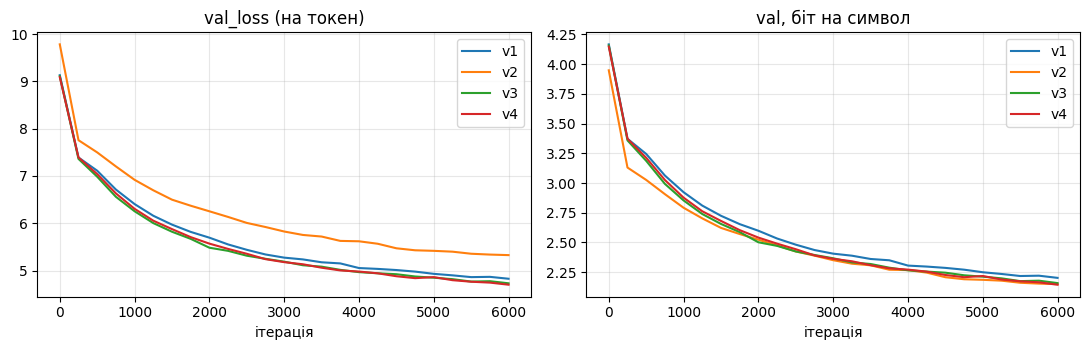

Найнижчий val_loss: v4_vocab8k_ctx64_L6 (4.728).
Найнижчий біт/символ: v2_vocab16k_ctx64_L4 (2.132).

Що змінилося відносно v1 (негативна різниця = краще):
  розмір словника 8k→16k   Δval_loss = +0.443   Δбіт/символ = -0.076   (параметрів +2,056,000, час +1.5 хв)
  контекст 64→128          Δval_loss = -0.100   Δбіт/символ = -0.046   (параметрів +8,192, час +3.0 хв)
  шарів 4→6                Δval_loss = -0.111   Δбіт/символ = -0.050   (параметрів +395,776, час +1.2 хв)

Найбільший виграш у біт/символ дала зміна: розмір словника 8k→16k (-0.076).
Чекпоінт з найкращим val_loss збігається з останнім у всіх варіантах.


In [23]:
sum_df = pd.DataFrame([{
    "варіант": s["run_name"], "словник": s["vocab"], "контекст": s["cfg"]["context_len"],
    "шарів": s["cfg"]["n_layers"], "параметрів": s["n_params"],
    "найкращий iter": s["best_iter"], "останній iter": s["last_iter"],
    "val_loss": round(s["val_loss"], 3), "perplexity": round(s["ppl"], 1),
    "біт/символ": round(s["bpc"], 3), "хв": round(s["minutes"], 1),
} for s in SUMMARY]).set_index("варіант")
display(sum_df)

# Криві навчання: зліва «сирий» val_loss, справа — перерахований у біти на символ
# (тільки він чесно порівнюється між різними словниками).
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for s in SUMMARY:
    h = HISTORIES[s["run_name"]]
    axes[0].plot(h["iters"], h["val"], label=s["tag"])
    axes[1].plot(h["iters"], [v / math.log(2) / s["chars_per_token"] for v in h["val"]], label=s["tag"])
axes[0].set_title("val_loss (на токен)"); axes[1].set_title("val, біт на символ")
for ax in axes:
    ax.set_xlabel("ітерація"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(LAB_DIR, "minigpt_val_curves.png"), dpi=130)
plt.show()

# --- висновок рахується з цифр
base = SUMMARY[0]
best_loss = min(SUMMARY, key=lambda s: s["val_loss"])
best_bpc = min(SUMMARY, key=lambda s: s["bpc"])
print(f"Найнижчий val_loss: {best_loss['run_name']} ({best_loss['val_loss']:.3f}).")
print(f"Найнижчий біт/символ: {best_bpc['run_name']} ({best_bpc['bpc']:.3f}).")
print("\nЩо змінилося відносно v1 (негативна різниця = краще):")
effects = {}
for s, what in zip(SUMMARY[1:], ["розмір словника 8k→16k", "контекст 64→128", "шарів 4→6"]):
    d_loss, d_bpc = s["val_loss"] - base["val_loss"], s["bpc"] - base["bpc"]
    effects[what] = d_bpc
    print(f"  {what:24s} Δval_loss = {d_loss:+.3f}   Δбіт/символ = {d_bpc:+.3f}   "
          f"(параметрів {s['n_params'] - base['n_params']:+,}, час {s['minutes'] - base['minutes']:+.1f} хв)")
top = min(effects, key=effects.get)
print(f"\nНайбільший виграш у біт/символ дала зміна: {top} ({effects[top]:+.3f}).")
overfit = [s["run_name"] for s in SUMMARY if s["best_iter"] != s["last_iter"]]
print("Чекпоінт з найкращим val_loss збігається з останнім у всіх варіантах." if not overfit
      else f"Найкращий чекпоінт раніший за останній у: {', '.join(overfit)} (ознака перенавчання).")

### 3.3. Генерація на найкращому чекпоінті

Один промпт і один seed для всіх варіантів; генерація зупиняється на `<eos>` або через 80 токенів. Кількість токенів однакова, а довжина тексту в символах відрізняється, бо в різних словників різна кількість символів на токен.

In [24]:
PROMPT = "Київ — місто"      # один і той самий промпт для всіх варіантів
GEN_TOKENS = 80
generations = {}

for s in SUMMARY:
    ckpt = torch.load(s["ckpt"], map_location=device)
    cfg = ckpt["config"]
    model = build_model(cfg, ckpt["vocab_size"])
    model.load_state_dict(ckpt["state_dict"])             # саме найкращий за val_loss чекпоінт
    tok = load_tokenizer(cfg["vocab_size"])
    prompt_ids = torch.tensor([tok.encode(PROMPT).ids], dtype=torch.long, device=device)
    set_seed(SEED)                                         # однаковий seed для чесності
    out = model.generate(prompt_ids, GEN_TOKENS, temperature=0.8, top_k=40,
                         stop_id=tok.token_to_id(EOS))
    text = tok.decode(out[0].tolist())
    generations[s["run_name"]] = text
    print(f"=== {s['run_name']}  (iter {ckpt['best_iter']}, val_loss={ckpt['val_loss']:.3f}) ===")
    print(text, "\n")
    del model, ckpt
    free()

with open(os.path.join(LAB_DIR, "generations.json"), "w", encoding="utf-8") as f:
    json.dump({"prompt": PROMPT, "generations": generations}, f, ensure_ascii=False, indent=2)

=== v1_baseline_vocab8k_ctx64_L4  (iter 5999, val_loss=4.826) ===
Київ — місто в КАГКЦДБЕРНГВИЗОВЕДЮАКА-ЛЬНВКК «ЗКАЛОНИОЛРЕФРАРЛИЙ-ХЬКИХИВОКЦОАРО України (У 1224—1928—184).

 

=== v2_vocab16k_ctx64_L4  (iter 5999, val_loss=5.326) ===
Київ — місто в Україні.

Нагороди 
 Профіль гравця  на сайті worldfootball.eu
 Профіль клубу на сайті transfermarkt.com
 Профіль гравця на офіційному сайті worldfootball.com
 Профіль клубу на сайті zerozero.pt
 Профіль клубу на сайті soccerpunter.com

Міста Айдахо
 Профіль клубу  на сайті footballdatabase.com
 Профіль клубу на сайті footballdatabase.com
 Профіль клубу  на сайті zerozero.eu
 Профіль 

=== v3_vocab8k_ctx128_L4  (iter 5999, val_loss=4.730) ===
Київ — місто в Україні або у складі 718,8 км2 осіб (6515-ме місце у світі).

У складі 62 році закінчив в Україні. Указом Президії Верховної Ради Міністрівознавець була одружений орденом «Бал-Малі», у тому числі 07-й, а також у світі.

Загалом провів 3-й хвилині з 94 матчі 

=== v4_vocab8k_ctx64_L6  (it

**Висновки по mini-GPT.** Усі цифри нижче з таблиці й виводу звіту вище.

*Хто виграв і чому це не так просто.* За «сирим» `val_loss` найкращий v4 (6 шарів, 4.728), а найгірший v2 (5.282). Але v2 це інший словник (16 000), тож loss на токен у нього не порівнюється з рештою: токени довші (3.57 символа проти 3.16), кожне передбачення важче, і loss на токен вищий. У бітах на символ, які від токенізації не залежать, картина обертається: v2 найкращий (2.132 проти 2.208 у бази). Це прямий приклад того, чому я рахувала біт/символ: за одним `val_loss` я б зробила хибний висновок.

*Що дало найбільший ефект (відносно v1, біт/символ).*

| зміна | Δ біт/символ | + параметрів | + часу тренування |
|---|---|---|---|
| словник 8k → 16k (v2) | −0.076 | +2.06 млн | +1.6 хв |
| глибина 4 → 6 шарів (v4) | −0.050 | +0.40 млн | +1.1 хв |
| контекст 64 → 128 (v3) | −0.046 | +8 тис. | +3.6 хв |

Найбільший виграш дав словник, але його «виграш» складається з двох речей, які я не розділяла: довші токени (вікно у 64 токени охоплює більше тексту) і +2 млн параметрів у матриці embedding та виходу (+72% до розміру моделі). Тож неправильно казати, що саме токенізація дала −0.076. У v3 параметрів майже не додалось, але вдвічі більший контекст означає вдвічі більше токенів за крок і вдвічі довший час, тож частина виграшу це «більше даних за крок», а не лише довша пам'ять. Якщо дивитись на виграш за кожну додаткову хвилину тренування, то найвигідніші v2 і v4 (≈ −0.045 біт/символ за хвилину), а v3 у кілька разів гірший (≈ −0.013).

*Перенавчання не було, навпаки.* У всіх чотирьох варіантів найкращий чекпоінт збігся з останнім (ітерація 5999), а `val_loss` ще падав до кінця. Це не перенавчання, а недотренованість: за 6000 кроків моделі не вийшли на плато, і більше ітерацій дало б ще виграш.

*Текст.* Усі чотири моделі крихітні (3–5 млн параметрів), тому текст має вікіпедичну форму, але не зміст. На промпт «Київ — місто» частина продовжень (v2, v4) з'їжджає у стиль коротких статей про футбольні клуби й гравців (статистика виступів, посилання на сайти): таких заготовок багато в моєму корпусі. Різниця між варіантами в тексті видна, але це одна вибірка з одним seed, тож висновки з неї лише ілюстративні:

- v1 видав довгий ряд великих літер («КАГКЦДБЕРНГВИЗОВЕДЮАКА…»): модель застрягла в заголовкоподібних токенах. За бітами на символ v1 справді найгірший (2.208), але різниця з рештою (2.13–2.16) невелика, а в тексті вона виглядає разючішою;
- v2 найзв'язніший за структурою (речення «Київ — місто в Україні.», розділи «Нагороди», «Профіль клубу на сайті…»), але впав у цикл із повторюваних рядків про зовнішні посилання;
- v3 і v4 дали правдоподібні за формою речення зі статистикою, датами й назвами клубів, але зміст безглуздий (v3: «6515-ме місце у світі»), як і слід очікувати від таких моделей.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

#### Звільняю пам'ять перед розділом 4

Спершу переконуюсь, що чекпоінти, токенізатори, `runs/` і `results.csv` уже лежать на диску, а потім видаляю великі об'єкти секцій 1–3 і перевіряю, що пам'ять справді звільнилась.

In [25]:
# 1) Спершу переконуюсь, що все важливе вже лежить на диску
save_results()
for folder in (MODELS_DIR, TOK_DIR):
    for name in sorted(os.listdir(folder)):
        print(f"  {os.path.relpath(os.path.join(folder, name), LAB_DIR):45s} "
              f"{os.path.getsize(os.path.join(folder, name)) / 1e6:7.1f} МБ")
print("  runs/:", sorted(os.listdir(RUNS_DIR)))

# 2) Видаляю великі об'єкти секцій 1-3 (корпус, дані, токенізатори, криві, тексти генерацій)
free("DATA", "HISTORIES", "SUMMARY", "docs", "corpus_text", "wiki_df", "words", "unique_words",
     "doc_lens", "cmp_tokenizers", "cmp_train", "cmp_eval", "old_tok", "new_tok", "probe_docs",
     "word_freqs", "splits", "model", "optimizer", "generations")

# 3) Перевірка, що пам'ять справді звільнилась
if torch.cuda.is_available():
    print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
try:
    import psutil
    print(f"RAM: зайнято {psutil.Process().memory_info().rss / 1e9:.2f} GB")
except ImportError:
    pass

results.csv оновлено: 87 рядків -> /content/drive/MyDrive/ai_systems/lab3/results.csv
  models/minigpt_v1.pt                             11.7 МБ
  models/minigpt_v2.pt                             20.0 МБ
  models/minigpt_v3.pt                             12.5 МБ
  models/minigpt_v4.pt                             13.5 МБ
  tokenizers/bpe_uk_wiki_16000.json                 1.5 МБ
  tokenizers/bpe_uk_wiki_8000.json                  0.7 МБ
  tokenizers/cmp_bpe_500.json                       0.0 МБ
  tokenizers/cmp_unigram_500.json                   0.0 МБ
  tokenizers/cmp_wordpiece_500.json                 0.0 МБ
  tokenizers/qwen_uk_warmup                         0.0 МБ
  runs/: ['v1_baseline_vocab8k_ctx64_L4', 'v2_vocab16k_ctx64_L4', 'v3_vocab8k_ctx128_L4', 'v4_vocab8k_ctx64_L6']
GPU: зайнято 0.02 GB
RAM: зайнято 5.97 GB


### 4.0. Запустіть приклади виконання різних NLP задач

In [26]:
!pip install "transformers[sentencepiece]==5.18.0"

In [27]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [28]:
free("classifier")

In [29]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [30]:
free("classifier")

In [31]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to use your own devices.\n\n\n\nYou can learn more about the course at https://www.youtube.com/watch?v=X7zYbzqN2jI\nThe course series is available on the Udemy website.\nThe courses are designed to help you complete the course and you can learn about using your own devices.\nYou can learn more about the course on Udemy http://www.youtube.com/watch?v=X7zYbzqN2jI\nThe course series is available on Udemy http://www.youtube.com/watch?v=X7zYbzqN2jI\nThe course series is available on the Udemy website.\nThe course series is available on the Udemy website.\nThe course series is available on the Udemy website.\nThe course series is available on the Udemy website.\nThe course series is available on the Udemy website.\nThe course series is available on the Udemy website.\nThe course series is available on the Udemy website.\nThe course series is available on the Udemy website.\nThe course series is available on the Udemy website.\nThe co

In [32]:
free("generator")

In [33]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [34]:
free("unmasker")

In [35]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [36]:
free("ner")

In [37]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

...

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

In [38]:
free("question_answerer")

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

Для української беру такі моделі (англомовні дефолти з прикладів вище української не знають):

| задача | модель | чому |
|---|---|---|
| sentiment-analysis | `cardiffnlp/twitter-xlm-roberta-base-sentiment` | багатомовна XLM-RoBERTa, в претрейні якої є українська |
| zero-shot-classification | `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` | багатомовна NLI-модель, мітки й шаблон гіпотези пишу українською |
| text-generation | `malteos/gpt2-uk` | GPT-2 (124 млн), навчений на українських текстах |
| fill-mask | `FacebookAI/xlm-roberta-base` | заповнення пропусків на 100 мовах, серед яких українська |
| NER | `ukr-models/uk-ner` | XLM-RoBERTa, дотренована на українських сутностях (PER/LOC/ORG) |
| table-question-answering | TAPAS (дефолт) і `Qwen/Qwen2.5-1.5B-Instruct` | для TAPAS української нема, тому додаю LLM як порівняння |

Після кожної задачі звільняю пам'ять.

#### Sentiment analysis

In [39]:
from transformers import pipeline

dev = 0 if torch.cuda.is_available() else -1      # індекс GPU для pipeline (-1 = CPU)

# Англійський sentiment-analysis за замовчуванням української не знає, тож беру багатомовну
# модель на основі XLM-RoBERTa (в її претрейні українська є).
classifier = pipeline("sentiment-analysis", model="cardiffnlp/twitter-xlm-roberta-base-sentiment", device=dev)

ukr_reviews = [
    "Цього тижня нарешті склав усі екзамени, почуваюся неймовірно щасливим!",
    "Потяг запізнився на три години, а в вагоні не працювало опалення. Жахливо.",
    "Звичайний вівторок, нічого особливого не сталося.",
    "Борщ у цій їдальні просто неперевершений, дякую кухарям!",
]
for text, res in zip(ukr_reviews, classifier(ukr_reviews)):
    print(f"{res['label']:9s} {res['score']:.2f} | {text}")

free("classifier")

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

positive  0.89 | Цього тижня нарешті склав усі екзамени, почуваюся неймовірно щасливим!
negative  0.88 | Потяг запізнився на три години, а в вагоні не працювало опалення. Жахливо.
positive  0.41 | Звичайний вівторок, нічого особливого не сталося.
positive  0.83 | Борщ у цій їдальні просто неперевершений, дякую кухарям!


#### Zero-shot classification

In [40]:
# Для zero-shot потрібна NLI-модель. Беру багатомовну mDeBERTa, а шаблон гіпотези пишу українською:
# для кожної мітки модель перевіряє, чи випливає з тексту «Цей текст про <мітка>».
ZS_MODEL = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"
classifier = pipeline("zero-shot-classification", model=ZS_MODEL, device=dev)

zs_texts = [
    "Збірна України з футболу вчора перемогла у відбірковому матчі з рахунком 3:1.",
    "Національний банк залишив облікову ставку без змін, інфляція сповільнилася.",
    "У Львові відкрилася виставка сучасних українських художників.",
]
zs_labels = ["спорт", "політика", "економіка", "культура", "технології"]
for text in zs_texts:
    res = classifier(text, candidate_labels=zs_labels, hypothesis_template="Цей текст про {}.")
    top3 = ", ".join(f"{l} {s:.2f}" for l, s in zip(res["labels"][:3], res["scores"][:3]))
    print(f"{text}\n   -> {top3}\n")

free("classifier")

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Збірна України з футболу вчора перемогла у відбірковому матчі з рахунком 3:1.
   -> спорт 0.99, політика 0.00, культура 0.00

Національний банк залишив облікову ставку без змін, інфляція сповільнилася.
   -> економіка 0.83, політика 0.13, технології 0.03

У Львові відкрилася виставка сучасних українських художників.
   -> культура 0.99, політика 0.00, економіка 0.00



#### Text generation

In [41]:
# Звичайний gpt2 знає лише англійську, тому беру malteos/gpt2-uk (GPT-2 на 124 млн параметрів,
# навчений на українських текстах). Це чиста мовна модель: вона продовжує текст, а не відповідає на запит.
generator = pipeline("text-generation", model="malteos/gpt2-uk", device=dev)
outputs = generator(
    "Одного разу в карпатському лісі",
    max_new_tokens=40, do_sample=True, top_k=50, temperature=0.9,
    num_return_sequences=2, pad_token_id=generator.tokenizer.eos_token_id,
)
for o in outputs:
    print(o["generated_text"], "\n" + "-" * 60)

free("generator")

config.json:   0%|          | 0.00/958 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  511MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: malteos/gpt2-uk
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/344 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'pad_token_id', 'top_k', 'temperature', 'num_return_sequences', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=40) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Одного разу в карпатському лісі чоловік побачив двох дітей, які стали батьками і постояли за його порадою. Через деякий час син повернувся додому і оселився в своїй квартирі в селі. Одного разу, повертаючись додому, він побачив їх 
------------------------------------------------------------
Одного разу в карпатському лісі неподалік від селища Великий Березний, де жили два брати: Андрій та Люба, хлопчик Назар та його молодша сестра Либідь... Я щиро вдячна Богу за те, що мій маленький брат і сестра зробили 
------------------------------------------------------------


#### Fill-mask

In [42]:
# XLM-RoBERTa вчили заповнювати пропуски на 100 мовах, серед яких українська.
unmasker = pipeline("fill-mask", model="FacebookAI/xlm-roberta-base", device=dev)
MASK = unmasker.tokenizer.mask_token      # у цієї моделі це <mask>, у BERT було б [MASK]

for sentence in [f"Тарас Шевченко — великий український {MASK}.",
                 f"Ми домовилися зустрітися о восьмій ранку біля {MASK}."]:
    print(sentence)
    for r in unmasker(sentence, top_k=4):
        print(f"   {r['token_str']:>14s}   {r['score']:.3f}")

free("unmasker")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Тарас Шевченко — великий український <mask>.
             поет   0.891
       письменник   0.026
         художник   0.024
       композитор   0.023
Ми домовилися зустрітися о восьмій ранку біля <mask>.
           церкви   0.163
             кафе   0.162
          будинку   0.137
            школи   0.086


#### Named entity recognition

In [43]:
# Український NER: XLM-RoBERTa, дотренована на розмітці PER / LOC / ORG.
from transformers import pipeline

dev = 0 if torch.cuda.is_available() else -1

# aggregation_strategy="first", а не "simple". Ця модель ставить мітку B- на кожен підтокен слова,
# тому зі "simple" слова розпадалися на уламки («Мо», «рин», «ці» як три окремі LOC).
# "first" спершу збирає підтокени в слова, бере мітку першого з них і лише потім склеює сусідні слова однієї сутності.
ner = pipeline("ner", model="ukr-models/uk-ner", aggregation_strategy="first", device=dev)

for sentence in [
    "Тарас Шевченко народився в селі Моринці на Черкащині, а навчався в Петербурзі.",
    "Компанія «Нова пошта» відкрила нове відділення у Львові поруч із Політехнікою.",
]:
    print(sentence)
    entities = ner(sentence)
    if entities:
        display(pd.DataFrame(entities)[["word", "entity_group", "score"]].round(3))
    else:
        print("   (сутностей не знайдено)")

free("ner")

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

...

/usr/local/lib/python3.13/dist-packages/transformers/pipelines/token_classification.py:444: UserWarning: Tokenizer does not support real words, using fallback heuristic
  warnings.warn(


,word,entity_group,score
0,ТарасШевченко,PER,1.0
1,Моринці,LOC,1.0
2,"Черкащині,",LOC,1.0
3,Петербурзі.,LOC,1.0


Компанія «Нова пошта» відкрила нове відділення у Львові поруч із Політехнікою.


/usr/local/lib/python3.13/dist-packages/transformers/pipelines/token_classification.py:444: UserWarning: Tokenizer does not support real words, using fallback heuristic
  warnings.warn(


,word,entity_group,score
0,пошта»,ORG,1.0
1,Львові,LOC,1.0
2,Політехнікою.,ORG,1.0


#### Table question answering

TAPAS навчали на англійських таблицях з англійським словником WordPiece, української в ньому фактично нема: кирилиця розбивається майже на окремі літери. Тому на українській таблиці він може помилятись, і перевірити це я хотів прямо. Для порівняння даю той самий запит невеликій LLM, якій таблиця подається текстом.

In [44]:
table = {
    "Місто": ["Київ", "Львів", "Харків", "Одеса"],
    "Населення, тис.": ["2952", "717", "1421", "1010"],
    "Область": ["м. Київ", "Львівська", "Харківська", "Одеська"],
}
questions = ["Яке населення у Львова?", "Яке місто має найбільше населення?"]

# Варіант 1: стандартний pipeline на TAPAS. Але TAPAS навчали на англійських таблицях з англійським
# словником, тож на українській він може помилятися — це видно з відповідей.
try:
    question_answerer = pipeline("table-question-answering", device=dev)
    for q in questions:
        res = question_answerer(table=table, query=q)
        print(f"[TAPAS] {q}  ->  {res['answer']}")
except Exception as e:      # на випадок, якщо в цій версії бібліотеки TAPAS недоступна
    print("⚠️ TAPAS у цьому середовищі не запустилась:", repr(e))

free("question_answerer")

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[TAPAS] Яке населення у Львова?  ->  AVERAGE > Київ
[TAPAS] Яке місто має найбільше населення?  ->  Київ


In [45]:
# Варіант 2: невелика інструктивна LLM, якій таблицю даємо текстом (markdown) разом із запитанням.
from transformers import AutoModelForCausalLM, AutoTokenizer

QA_LLM = "Qwen/Qwen2.5-1.5B-Instruct"
qa_tok = AutoTokenizer.from_pretrained(QA_LLM)
qa_lm = AutoModelForCausalLM.from_pretrained(
    QA_LLM, dtype=torch.float16 if torch.cuda.is_available() else torch.float32
).to(device)

table_md = "| " + " | ".join(table) + " |\n|" + "---|" * len(table) + "\n" + "\n".join(
    "| " + " | ".join(table[c][i] for c in table) + " |" for i in range(len(table["Місто"])))
for q in questions:
    messages = [{"role": "user",
                 "content": f"Таблиця:\n{table_md}\n\nДай коротку відповідь українською, лише по таблиці.\nПитання: {q}"}]
    prompt = qa_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = qa_tok([prompt], return_tensors="pt").to(device)
    out = qa_lm.generate(**inputs, max_new_tokens=40, do_sample=False)
    print(f"[{QA_LLM.split('/')[1]}] {q}  ->  "
          f"{qa_tok.decode(out[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True).strip()}")
free("qa_lm", "qa_tok")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[Qwen2.5-1.5B-Instruct] Яке населення у Львова?  ->  Населення у Львові - 717 тис.
[Qwen2.5-1.5B-Instruct] Яке місто має найбільше населення?  ->  Київ


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

### 5.1. Задача і метрика

Обираю **sentiment-analysis**. Метрики: `accuracy` та `F1` (клас «позитивний» = 1) через `evaluate`. Дані: 20 моїх речень (10 позитивних, 10 негативних). Серед них навмисно є складні випадки: заперечення при позитивному змісті («не можу сказати, що фільм був поганим, навпаки...»), іронія («ну так, чудово, знову скасували потяг...») та побутова лексика. Гарантувати, що всі моделі розуміють саме ці приклади, не можна, і саме це я й хочу перевірити.

Моделі мають різні набори міток (negative/neutral/positive або від 1 до 5 зірок), тому всі виходи приводжу до єдиного вектора `[neg, neu, pos]`: зірки 1–2 — негатив, 3 — нейтрально, 4–5 — позитив.

In [46]:
import evaluate
from transformers import pipeline

# Обрана задача: sentiment-analysis, метрики accuracy та F1 (позитивний клас = 1).
# 20 власних речень: 10 позитивних і 10 негативних. Серед них навмисно є «підступні»:
# заперечення при позитивному змісті (№8), іронія (№16), побутовий сленг.
SENT_DATA = [
    ("Сьогодні чудова погода, настрій просто відмінний!", 1),
    ("Дуже вдячний вам за допомогу, ви мене неймовірно виручили.", 1),
    ("У цій кав'ярні найсмачніші сирники в місті, обов'язково прийду ще.", 1),
    ("Лекція була цікавою, а викладач пояснює так, що все стає зрозумілим.", 1),
    ("Нарешті склав сесію без боргів, просто щасливий!", 1),
    ("Новий телефон працює швидко, а камера робить прекрасні знімки.", 1),
    ("Мені дуже сподобалась екскурсія, гід розповідав захопливо.", 1),
    ("Не можу сказати, що фільм був поганим, навпаки, дивився із задоволенням.", 1),
    ("Наша команда виграла матч, і вся країна святкує!", 1),
    ("Доставка прийшла раніше терміну, а товар навіть кращий, ніж на фото.", 1),
    ("Жахливий сервіс: чекали замовлення годину, а офіціант навіть не вибачився.", 0),
    ("Інтернет знову не працює, це неймовірно дратує.", 0),
    ("Фільм виявився нудним, я ледве додивився до кінця.", 0),
    ("Купив навушники, а вони зламалися за тиждень. Гроші викинуті на вітер.", 0),
    ("Мені дуже прикро, що так сталося, день абсолютно зіпсований.", 0),
    ("Ну так, чудово, знову скасували потяг саме тоді, коли я поспішаю.", 0),
    ("Викладач не пояснює матеріал, а лекції схожі на читання з підручника.", 0),
    ("Дуже розчарований поїздкою: брудний номер і грубий персонал.", 0),
    ("Ціни зростають, зарплата стоїть на місці, настрій жахливий.", 0),
    ("Додаток постійно вилітає, користуватися ним неможливо.", 0),
]
texts = [t for t, _ in SENT_DATA]
gold = [y for _, y in SENT_DATA]
print(f"Речень: {len(texts)}, позитивних: {sum(gold)}, негативних: {len(gold) - sum(gold)}")

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

# Моделі мають різні набори міток: negative/neutral/positive або «1 star»...«5 stars».
# Приводжу все до єдиного вектора ймовірностей [neg, neu, pos].
IDX = {"negative": 0, "neutral": 1, "positive": 2}


def polarity(label: str) -> str:
    l = label.lower().strip()
    if l.startswith("label_"):
        l = {"label_0": "negative", "label_1": "neutral", "label_2": "positive"}.get(l, l)
    m = re.match(r"(\d)\s*star", l)
    if m:
        n = int(m.group(1))
        return "negative" if n <= 2 else ("neutral" if n == 3 else "positive")
    if "neg" in l:
        return "negative"
    if "pos" in l:
        return "positive"
    return "neutral"


def to_probs(one_result) -> np.ndarray:
    if isinstance(one_result, dict):
        one_result = [one_result]
    p = np.zeros(3)
    for d in one_result:
        p[IDX[polarity(d["label"])]] += d["score"]
    return p


def run_model(clf, batch_texts) -> np.ndarray:
    out = clf(batch_texts, top_k=None, batch_size=8)       # top_k=None -> ймовірності ВСІХ міток
    return np.stack([to_probs(r) for r in out])


def decide(P: np.ndarray, mode: str = "binary", thr: float = 0.5) -> np.ndarray:
    p_neg, p_pos = P[:, 0], P[:, 2]
    if mode == "binary":                  # порівнюємо лише «за» і «проти»; поріг thr для частки позитиву
        return (p_pos / np.clip(p_pos + p_neg, 1e-9, None) >= thr).astype(int)
    if mode == "allow_neutral":           # модель може відповісти «нейтрально», а в золоті нейтральних немає
        top = P.argmax(1)
        pred = np.where(top == 2, 1, 0)
        return np.where(top == 1, 1 - np.array(gold), pred)    # нейтральна відповідь = гарантована помилка
    raise ValueError(mode)


def score(pred) -> tuple:
    pred = [int(x) for x in pred]
    return (accuracy_metric.compute(predictions=pred, references=gold)["accuracy"],
            f1_metric.compute(predictions=pred, references=gold)["f1"])


# швидка перевірка допоміжних функцій на вигаданих виходах моделей
assert to_probs([{"label": "Positive", "score": .7}, {"label": "Negative", "score": .2}, {"label": "Neutral", "score": .1}]).tolist() == [0.2, 0.1, 0.7]
assert polarity("4 stars") == "positive" and polarity("2 stars") == "negative" and polarity("LABEL_0") == "negative"

Речень: 20, позитивних: 10, негативних: 10


### 5.2. Порівняння моделей

Три багатомовні моделі на однакових 20 реченнях: якість (accuracy, F1), розмір (кількість параметрів) і швидкість (медіана часу з трьох прогонів на всіх 20 реченнях після прогріву). Для кожної моделі відразу готую ймовірності на трьох варіантах вхідного тексту (як є, нижній регістр, без пунктуації), щоб у 5.3 не завантажувати моделі повторно.

In [47]:
dev = 0 if torch.cuda.is_available() else -1

SENT_MODELS = {   # коротка назва -> id на Hugging Face
    "xlmr-base-twitter": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "mdistilbert-student": "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "mbert-5stars": "nlptown/bert-base-multilingual-uncased-sentiment",
}
# Варіанти вхідного тексту для 5.3: готуємо відразу, щоб кожну модель завантажити лише раз.
INPUT_VARIANTS = {
    "raw": texts,
    "lowercase": [t.lower() for t in texts],
    "no_punct": [re.sub(r"[^\w\s]", "", t) for t in texts],
}


def time_inference(clf, batch_texts, repeats: int = 3) -> float:
    """Медіана часу обробки всього набору (після прогріву)."""
    run_model(clf, batch_texts[:2])
    times = []
    for _ in range(repeats):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        run_model(clf, batch_texts)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


model_info = {}
for name, model_id in SENT_MODELS.items():
    clf = pipeline("sentiment-analysis", model=model_id, device=dev)
    info = {"id": model_id, "params": sum(p.numel() for p in clf.model.parameters())}
    info["seconds"] = time_inference(clf, texts)
    info["P"] = {variant: run_model(clf, variant_texts) for variant, variant_texts in INPUT_VARIANTS.items()}
    info["acc"], info["f1"] = score(decide(info["P"]["raw"]))
    model_info[name] = info
    log_result("sentiment_models", name, f"{model_id};n={len(texts)}", "accuracy", info["acc"])
    log_result("sentiment_models", name, f"{model_id};n={len(texts)}", "f1", info["f1"])
    log_result("sentiment_models", name, f"{model_id};n={len(texts)}", "params_millions", info["params"] / 1e6)
    log_result("sentiment_models", name, f"{model_id};n={len(texts)}", "seconds_for_20_sentences", info["seconds"])
    del clf
    free()
save_results()

models_df = pd.DataFrame([{
    "модель": n, "параметрів, млн": round(i["params"] / 1e6, 1),
    "час на 20 речень, с": round(i["seconds"], 3), "мс / речення": round(1000 * i["seconds"] / len(texts), 1),
    "accuracy": round(i["acc"], 3), "F1": round(i["f1"], 3),
} for n, i in model_info.items()]).set_index("модель")
display(models_df)

best_name = max(model_info, key=lambda n: (model_info[n]["acc"], model_info[n]["f1"], -model_info[n]["seconds"]))
print(f"\nНайкращий за accuracy: {best_name} ({model_info[best_name]['acc']:.2f}).")
fastest = min(model_info, key=lambda n: model_info[n]["seconds"])
smallest = min(model_info, key=lambda n: model_info[n]["params"])
print(f"Найшвидша: {fastest}; найменша за розміром: {smallest}.")

# Які саме речення кожна модель завалила (при базовому рішенні)
for n, i in model_info.items():
    wrong = [k + 1 for k, (p, g) in enumerate(zip(decide(i["P"]["raw"]), gold)) if p != g]
    print(f"  {n:22s} помилки на реченнях №: {wrong or '—'}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

...

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

results.csv оновлено: 87 рядків -> /content/drive/MyDrive/ai_systems/lab3/results.csv


,"параметрів, млн","час на 20 речень, с",мс / речення,accuracy,F1
модель,,,,,
xlmr-base-twitter,278.0,0.068,3.4,0.95,0.952
mdistilbert-student,135.3,0.042,2.1,0.65,0.588
mbert-5stars,167.4,0.070,3.5,0.85,0.842



Найкращий за accuracy: xlmr-base-twitter (0.95).
Найшвидша: mdistilbert-student; найменша за розміром: mdistilbert-student.
  xlmr-base-twitter      помилки на реченнях №: [16]
  mdistilbert-student    помилки на реченнях №: [1, 2, 5, 7, 8, 17, 20]
  mbert-5stars           помилки на реченнях №: [8, 10, 18]


### 5.3. Налаштування по одному

Базове рішення: порівнюю лише «позитив» проти «негатив» і ставлю клас «позитивний», якщо його частка не менша за 0.5. Далі міняю **по одному налаштуванню за раз**: поріг (0.3 і 0.7), дозвіл моделі відповідати «нейтрально» (тоді таке передбачення рахується помилкою, бо в золотому наборі нейтральних нема), нижній регістр, прибрана пунктуація. Таблицю роблю для всіх моделей, а акцент — на найкращій.

In [48]:
# 5.3: налаштування змінюю ПО ОДНОМУ, відносно базового (binary, поріг 0.5, текст як є).
SETTINGS = {   # назва -> (вхідний текст, режим рішення, поріг)
    "база: поріг 0.5":            ("raw",       "binary",        0.5),
    "поріг позитиву 0.3":         ("raw",       "binary",        0.3),
    "поріг позитиву 0.7":         ("raw",       "binary",        0.7),
    "дозволити «нейтрально»":     ("raw",       "allow_neutral", 0.5),
    "текст у нижньому регістрі":  ("lowercase", "binary",        0.5),
    "текст без пунктуації":       ("no_punct",  "binary",        0.5),
}
grid_acc, grid_f1 = {}, {}
for mname, info in model_info.items():
    for sname, (variant, mode, thr) in SETTINGS.items():
        acc, f1 = score(decide(info["P"][variant], mode, thr))
        grid_acc[(mname, sname)], grid_f1[(mname, sname)] = acc, f1
        log_result("sentiment_settings", mname, sname, "accuracy", acc)
        log_result("sentiment_settings", mname, sname, "f1", f1)
save_results()

acc_table = pd.Series(grid_acc).unstack().loc[list(model_info), list(SETTINGS)]
f1_table = pd.Series(grid_f1).unstack().loc[list(model_info), list(SETTINGS)]
print("Accuracy (рядки — моделі, стовпці — налаштування):")
display(acc_table.round(2))
print("F1:")
display(f1_table.round(2))

best_cell = acc_table.stack().idxmax()
model_spread = acc_table["база: поріг 0.5"].max() - acc_table["база: поріг 0.5"].min()
setting_spread = acc_table.loc[best_name].max() - acc_table.loc[best_name].min()
print(f"Найкраща комбінація за accuracy: {best_cell[0]} + «{best_cell[1]}» = {acc_table.stack().max():.2f}")
print(f"Розкид між моделями при базових налаштуваннях: {model_spread:.2f}")
print(f"Розкид між налаштуваннями для найкращої моделі ({best_name}): {setting_spread:.2f}")
verdict = ("Вибір моделі вплинув сильніше, ніж налаштування." if model_spread > setting_spread
           else "Налаштування вплинули сильніше, ніж вибір моделі." if model_spread < setting_spread
           else "Вплив вибору моделі і налаштувань однаковий.")
print(verdict)

results.csv оновлено: 87 рядків -> /content/drive/MyDrive/ai_systems/lab3/results.csv
Accuracy (рядки — моделі, стовпці — налаштування):


,база: поріг 0.5,поріг позитиву 0.3,поріг позитиву 0.7,дозволити «нейтрально»,текст у нижньому регістрі,текст без пунктуації
xlmr-base-twitter,0.95,0.90,0.95,0.90,0.95,0.95
mdistilbert-student,0.65,0.70,0.65,0.65,0.75,0.75
mbert-5stars,0.85,0.85,0.90,0.85,0.85,0.90


F1:


,база: поріг 0.5,поріг позитиву 0.3,поріг позитиву 0.7,дозволити «нейтрально»,текст у нижньому регістрі,текст без пунктуації
xlmr-base-twitter,0.95,0.91,0.95,0.91,0.95,0.95
mdistilbert-student,0.59,0.70,0.46,0.59,0.71,0.71
mbert-5stars,0.84,0.86,0.89,0.84,0.84,0.89


Найкраща комбінація за accuracy: xlmr-base-twitter + «база: поріг 0.5» = 0.95
Розкид між моделями при базових налаштуваннях: 0.30
Розкид між налаштуваннями для найкращої моделі (xlmr-base-twitter): 0.05
Вибір моделі вплинув сильніше, ніж налаштування.


**Висновок.** Найкраща модель `xlmr-base-twitter` (accuracy 0.95, F1 0.95): помилилась лише на реченні №16 («Ну так, чудово, знову скасували потяг…»), тобто на іронії. `mbert-5stars` дала 0.85 (помилки на №8 із запереченням, №10 і №18). `mdistilbert-student` лише 0.65: сім помилок, і п'ять із них це позитивні речення (№1, 2, 5, 7, 8), які вона назвала негативними. Найменша й найшвидша модель (135 млн параметрів, 2.1 мс на речення) виявилась найгіршою, а найкраща не найповільніша: 3.5 мс на речення проти 3.6 в `mbert-5stars`. На 20 реченнях швидкість узагалі не стає аргументом.

Вибір моделі вплинув сильніше за налаштування: розкид між моделями при базових налаштуваннях 0.30 (шість речень), а між налаштуваннями для найкращої моделі лише 0.05 (одне речення, тобто в межах шуму).

Як поводились налаштування:

- **Поріг.** Для найкращої моделі поріг 0.3 навіть зашкодив (0.95 → 0.90), а 0.7 нічого не змінив: вона й так добре відкалібрована. Для слабкої `mdistilbert` поріг 0.3 допоміг (accuracy 0.65 → 0.70, F1 0.59 → 0.70). Це логічно, бо вона систематично недооцінює позитив, і зсув порога частково це лікує; поріг 0.7 навпаки опустив її F1 до 0.46. Для `mbert-5stars` поріг 0.7 дав +0.05.
- **«Нейтрально».** Дозвіл відповідати нейтрально знизив лише найкращу модель (0.95 → 0.90): на одному реченні вона обирає нейтральний клас там, де в нашому наборі позитив чи негатив. Решті нічого не змінив.
- **Регістр і пунктуація.** Помітний ефект тільки в `mdistilbert` (cased): нижній регістр і прибрана пунктуація підняли accuracy з 0.65 до 0.75. У `mbert-5stars` (uncased) нижній регістр не змінив нічого, бо вона й так переводить текст у нижній регістр, а прибрана пунктуація дала 0.85 → 0.90. XLM-R не зреагувала на жодне з двох.
- **Застереження.** Одне речення це 5 пунктів accuracy, тож зміни на 0.05 це шум, а надійний лише великий розрив між моделями (0.95 проти 0.65). Для певних висновків потрібна вибірка в сотні прикладів.

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

### «Перед публікацією»

Застосунок для чернетки допису (чат групи, коментар під новиною, пост): перед відправкою показує те, що автор часто не помічає.

1. **Тон**: чи не надто різкий (sentiment-модель, найкраща з розділу 5).
2. **Тема**: до чого належить текст. Категорії **задає сам користувач**, бо це zero-shot (mDeBERTa); можна ввести хоч «сесія, гуртожиток, стипендія».
3. **Що текст розкриває про автора**: NER (`ukr-models/uk-ner`) підсвічує імена, місця й організації, а регулярні вирази ловлять телефони та e-mail. Усе це в одному кольоровому тексті.

Окремо під результатом друкуються поради: чи є контактні дані, чи згадано людей, чи тон різкий. Всі три моделі вже знайомі з розділів 4–5, а нового тут — їх поєднання в одну корисну дію.

Клітинка запускає застосунок; у Colab він з'явиться за публічним посиланням `gradio.live`. Модель для тону береться з розділу 5 (найкраща за accuracy), а якщо розділ 5 у цій сесії не виконувався, використовується `cardiffnlp/twitter-xlm-roberta-base-sentiment`. Для NER обрано `aggregation_strategy="first"`: зі стандартним `"simple"` ця модель розбивала слова на уламки.

In [49]:
import gradio as gr
from transformers import pipeline

# «Перед публікацією»: для чернетки допису (чат групи, коментар, пост) показує
#   1) тон: чи не занадто різкий;  2) тему (категорії задає сам користувач, це zero-shot);
#   3) що текст розкриває про автора: імена, місця, організації, телефони, e-mail.
APP_SENT_MODEL = SENT_MODELS[best_name] if "best_name" in globals() else "cardiffnlp/twitter-xlm-roberta-base-sentiment"
dev = 0 if torch.cuda.is_available() else -1
sent_pipe = pipeline("sentiment-analysis", model=APP_SENT_MODEL, device=dev)
zs_pipe = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7", device=dev)
ner_pipe = pipeline("ner", model="ukr-models/uk-ner", aggregation_strategy="first", device=dev)

# Допоміжні функції для тону (ті самі, що в розділі 5, продубльовані, щоб клітинка працювала й окремо)
def app_polarity(label: str) -> str:
    l = label.lower().strip()
    if l.startswith("label_"):
        l = {"label_0": "negative", "label_1": "neutral", "label_2": "positive"}.get(l, l)
    m = re.match(r"(\d)\s*star", l)
    if m:
        n = int(m.group(1))
        return "negative" if n <= 2 else ("neutral" if n == 3 else "positive")
    return "negative" if "neg" in l else ("positive" if "pos" in l else "neutral")


def app_probs(one_result) -> np.ndarray:
    """-> вектор [neg, neu, pos]"""
    p = np.zeros(3)
    for d in (one_result if isinstance(one_result, list) else [one_result]):
        p["negative neutral positive".split().index(app_polarity(d["label"]))] += d["score"]
    return p

PHONE = re.compile(r"(?:\+?38[\s-]?)?\(?0\d{2}\)?[\s-]?\d{3}[\s-]?\d{2}[\s-]?\d{2}")
EMAIL = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")
ENT_NAMES = {"PER": "особа", "PERS": "особа", "LOC": "місце", "ORG": "організація", "MISC": "інше"}
DEFAULT_TOPICS = "навчання, робота, гроші, здоров'я, дозвілля, політика"


def merge_spans(text: str, spans):
    """Склеює знайдені фрагменти (початок, кінець, мітка) з рештою тексту для HighlightedText.
    Якщо фрагменти перекриваються, лишається той, що починається раніше (при рівності — довший)."""
    out, pos = [], 0
    for s, e, label in sorted(spans, key=lambda x: (x[0], -(x[1] - x[0]))):
        if s < pos:
            continue
        if s > pos:
            out.append((text[pos:s], None))
        out.append((text[s:e], label))
        pos = e
    if pos < len(text):
        out.append((text[pos:], None))
    return out


def analyze(text: str, topics_csv: str):
    text = (text or "").strip()
    if not text:
        return {}, {}, [], "Спершу введіть текст."
    topics = [t.strip() for t in (topics_csv or "").split(",") if t.strip()] or DEFAULT_TOPICS.split(", ")

    zs = zs_pipe(text, candidate_labels=topics, hypothesis_template="Цей текст про {}.")
    topic_scores = {l: float(s) for l, s in zip(zs["labels"], zs["scores"])}

    p_neg, p_neu, p_pos = app_probs(sent_pipe([text], top_k=None)[0])
    tone = {"негативний": float(p_neg), "нейтральний": float(p_neu), "позитивний": float(p_pos)}

    spans = [(e["start"], e["end"], ENT_NAMES.get(e["entity_group"], e["entity_group"])) for e in ner_pipe(text)]
    spans += [(m.start(), m.end(), "телефон") for m in PHONE.finditer(text)]
    spans += [(m.start(), m.end(), "e-mail") for m in EMAIL.finditer(text)]

    notes = []
    contacts = len(PHONE.findall(text)) + len(EMAIL.findall(text))
    if contacts:
        notes.append(f"⚠️ У тексті є контактні дані ({contacts}). Чи справді їх варто публікувати відкрито?")
    people = [t for t, l in merge_spans(text, spans) if l == "особа"]
    if people:
        notes.append(f"👤 Згадано людей: {', '.join(people)}. Чи вони не проти?")
    if p_neg > 0.6:
        notes.append("🌡️ Тон помітно негативний. Перечитайте ще раз, чи не надто різко.")
    if not notes:
        notes.append("✅ Нічого тривожного не знайдено.")
    return topic_scores, tone, merge_spans(text, spans), "\n\n".join(notes)


with gr.Blocks(title="Перед публікацією") as demo:
    gr.Markdown("# 📝 Перед публікацією\nВставте чернетку допису — подивіться на тон, тему і те, що текст розкриває про вас.")
    with gr.Row():
        with gr.Column():
            inp = gr.Textbox(lines=7, label="Чернетка", placeholder="Напишіть або вставте текст українською...")
            topics_in = gr.Textbox(value=DEFAULT_TOPICS, label="Теми для розпізнавання (через кому; можна свої)")
            btn = gr.Button("Перевірити", variant="primary")
        with gr.Column():
            tone_out = gr.Label(label="Тон", num_top_classes=3)
            topic_out = gr.Label(label="Тема", num_top_classes=4)
            notes_out = gr.Markdown()
    ents_out = gr.HighlightedText(label="Що розкриває текст", show_legend=True)
    btn.click(analyze, inputs=[inp, topics_in], outputs=[topic_out, tone_out, ents_out, notes_out])
    gr.Examples(
        examples=[
            ["Завтра о 18:00 зустрічаємось біля Політехніки, дзвони мені на 097 123 45 67. Петро Іваненко теж буде.", DEFAULT_TOPICS],
            ["Знову відключили світло, а я завтра здаю проєкт. Це просто знущання, терпіти більше не можу!", DEFAULT_TOPICS],
            ["Здав сесію на відмінно, мама пише на ivan.petrenko@example.com, що пишається мною.", "навчання, родина, спорт, подорожі"],
        ],
        inputs=[inp, topics_in],
    )

demo.launch(debug=False)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3a2c8ce95dde293185.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```

In [50]:
save_results()
need_models = [f"minigpt_v{i}.pt" for i in range(1, 5)]
for name in need_models:
    print("✓" if os.path.exists(os.path.join(MODELS_DIR, name)) else "✗", "models/" + name)
runs = sorted(os.listdir(RUNS_DIR)) if os.path.isdir(RUNS_DIR) else []
print("✓" if runs else "✗", "runs/", runs)
print("✓" if os.path.exists(RESULTS_CSV) else "✗", "results.csv")
display(pd.read_csv(RESULTS_CSV).groupby("section").size().rename("рядків").to_frame())
print("\nНа Drive папка лежить тут:", LAB_DIR)
print("Скопіюйте її вміст у /lab3/ репозиторію разом з обома ноутбуками (збереженими з виводом).")

results.csv оновлено: 87 рядків -> /content/drive/MyDrive/ai_systems/lab3/results.csv
✓ models/minigpt_v1.pt
✓ models/minigpt_v2.pt
✓ models/minigpt_v3.pt
✓ models/minigpt_v4.pt
✓ runs/ ['v1_baseline_vocab8k_ctx64_L4', 'v2_vocab16k_ctx64_L4', 'v3_vocab8k_ctx128_L4', 'v4_vocab8k_ctx64_L6']
✓ results.csv


,рядків
section,
minigpt,24
sentiment_models,12
sentiment_settings,36
tokenizers,15



На Drive папка лежить тут: /content/drive/MyDrive/ai_systems/lab3
Скопіюйте її вміст у /lab3/ репозиторію разом з обома ноутбуками (збереженими з виводом).
